# debug — math walkthrough and numerical checks

Writes out the formulas step by step following the pipeline's math, and after each function is implemented calls it for numerical checks (hand-computed comparisons, shapes, NaN, causality).
Not every function has to appear here; no full-sample backtest is run here and nothing is written to `outputs/` (§8 saves to a temporary directory; formal runs are `run.ipynb`'s job).

Each subsection has two code cells: the first only makes the normal call and shows each stock's result on `AS_OF`; the second is dedicated to checks (hand-computed comparisons, causality, NaN, edge cases and errors) and produces no output if everything passes.

### Notation

| Symbol | Meaning |
| --- | --- |
| $i$, $t$ | Stock, trading day |
| $t_0$ | Decision date as_of |
| $P_{i,t}$ | Close price (given by `DataSpec.price_col`) |
| $r_{i,t}$ | Daily simple return, decimal |
| $N_t$ | Set of stocks whose factor value on day $t$ is non-NaN |
| $H$ | Holding period (trading days) |
| $A$ | Number of periods per year, `TaskSpec.periods_per_year` (252) |

In [ ]:
%load_ext autoreload
%autoreload 2

import json
import re
import tempfile
import warnings
from dataclasses import asdict, replace
from pathlib import Path
from unittest.mock import patch

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, set_link_color_palette
from sklearn.covariance import LedoitWolf

import pf.backtest
import pf.cluster
import pf.config
import pf.factors
import pf.knn
import pf.loader
import pf.metrics
import pf.scoring
import pf.selection
import pf.weights

AS_OF = pd.Timestamp("2026-06-30")  # single as_of used for checks: must be a trading day with data; does not use decision_date
TICKER = "MSFT"                     # example stock for hand-computed comparisons

## 1. Prices and returns

$$
r_{i,t} = \frac{P_{i,t}}{P_{i,t-1}} - 1
$$

Late-listed stocks (MPC, NOW, ABBV, AAOI, ONDS, TEM, CRWV) have no prices before listing; the corresponding $P$ and $r$ are NaN and must not be filled.

In [2]:
cfg = pf.config.Config()
prices = pf.loader.load_prices(cfg.data.price_file, cfg.data.price_col)
returns = prices.pct_change(fill_method=None)  # no forward filling: CRWV's r stays NaN before listing
benchmarks = pf.loader.load_benchmarks(cfg.data.benchmark_file)  # used by ret (knn) and clustering (remove_market)

print(prices.shape, prices.index[0].date(), "→", prices.index[-1].date())
prices.tail()

(3956, 28) 2011-01-03 → 2026-09-25


ticker,AAOI,ABBV,AVGO,BAC,BRK-B,CAT,CRWV,EOG,GE,GOOGL,...,MPC,MSFT,MSTR,NEM,NOW,ONDS,TEM,V,WMT,XOM
date,,,,,,,,,,,,,,,,,,,,,
2026-09-21,108.669998,264.480011,362.660004,57.959999,502.010010,816.500000,85.430000,141.380005,319.010010,354.970001,...,402.380005,501.609985,168.500000,123.050003,137.679993,7.38,78.029999,369.950012,107.440002,158.300003
2026-09-22,107.000000,265.209991,364.540009,56.200001,503.489990,808.010010,86.760002,139.520004,319.220001,351.160004,...,389.679993,498.000000,167.330002,127.260002,137.000000,7.72,77.190002,362.040009,110.120003,158.710007
2026-09-23,101.059998,265.079987,354.989990,56.000000,507.170013,812.020020,86.900002,141.839996,319.799988,337.829987,...,388.380005,500.589996,162.199997,123.550003,140.779999,7.40,76.589996,361.519989,110.529999,161.229996
2026-09-24,101.029999,265.119995,350.359985,56.029999,505.179993,805.250000,90.129997,142.860001,319.779999,342.359985,...,390.950012,497.929993,161.610001,121.300003,137.779999,7.60,82.239998,367.980011,107.589996,162.139999
2026-09-25,101.400002,264.339996,352.809998,56.700001,505.480011,821.580017,87.589996,140.350006,327.089996,343.920013,...,393.519989,516.169983,158.610001,121.430000,135.619995,7.64,85.010002,367.380005,107.980003,160.589996


In [ ]:
# Checks (no output if everything passes)
# Check the price table's shape and date range, and that the index is ascending and unique
assert prices.shape == (3957, 31)
assert prices.index[0] == pd.Timestamp("2011-01-03") and prices.index[-1] == pd.Timestamp("2026-09-28")
assert prices.index.is_monotonic_increasing and prices.index.is_unique

# Each stock is all NaN before listing and has no NaN after listing
crwv_start = pd.Timestamp("2025-03-28")
listed = {"MPC": "2011-06-24", "NOW": "2012-06-29", "ABBV": "2013-01-02", "AAOI": "2013-09-26",
          "ONDS": "2020-12-04", "TEM": "2024-06-14", "CRWV": "2025-03-28"}
first = prices.apply(pd.Series.first_valid_index)
expected_first = pd.Series({t: pd.Timestamp(listed.get(t, "2011-01-03")) for t in prices.columns})
pd.testing.assert_series_equal(first, expected_first, check_names=False)
for t in prices.columns:
    assert prices.loc[first[t]:, t].notna().all(), t

# Benchmark indices: all 6 indices and the risk-free rate ^IRX are present, DataSpec.benchmark is one of them; no all-NaN dates
assert list(benchmarks.columns) == ["^DJI", "^GSPC", "^IRX", "^IXIC", "^NDX", "^RUT", "^VIX"]
assert cfg.data.benchmark in benchmarks.columns
assert benchmarks.notna().any(axis=1).all()

# TICKER's r on AS_OF matches the hand-computed P_t / P_{t-1} - 1 (previous trading day taken by row position)
i = prices.index.get_loc(AS_OF)
assert np.isclose(returns.loc[AS_OF, TICKER], prices[TICKER].iloc[i] / prices[TICKER].iloc[i - 1] - 1)

## 2. as_of truncation and causality

Information available after the close on decision date $t_0$:

$$
\mathcal{I}_{t_0} = \{P_{i,t} : t \le t_0\} \;\cup\; \{\text{fundamentals records} : \text{ann\_date} < t_0\}
$$

Fundamentals use **strictly less than**: the announcement time is unknown, and an after-hours announcement is not available at that day's close.

**Causality check**: a factor function computes only the single day $t_0$ and should only use rows on and before $t_0$, so

$$
F(\text{prices}_{\le t_0},\ t_0) = F(\text{prices},\ t_0)
$$

If they differ, the factor used future data.

In [4]:
# Each factor's causality check is in its own subsection of §3

## 3. Factors (raw values)

Each factor is computed only on the single day `AS_OF` and outputs `Series[ticker]`. All factors are higher-is-better: factors that need reversing are negated inside the factor function, and the combination in §4 no longer handles direction.
When the computation needs unavailable data, only that stock is NaN.

### 3.1 momentum

$t$ is the row position of as_of (counted in trading days, not calendar days), $L$ = `lookback`, $S$ = `skip`, $L > S \ge 0$:

$$
\mathrm{MOM}_{i,t} = \frac{P_{i,\,t-S}}{P_{i,\,t-L}} - 1
$$

Stocks missing $P_{i,t-L}$ or $P_{i,t-S}$ are NaN without affecting other stocks (e.g. `CRWV` when listed fewer than $L$ days).
All NaN when there are fewer than $L$ rows before as_of. No volatility adjustment.

In [5]:
momentum = pf.factors.FACTORS["momentum"]
mp = cfg.factors.momentum
L, S = mp.lookback, mp.skip
mom = momentum(prices, None, AS_OF, lookback=L, skip=S)

# Each stock's result on AS_OF, with the start and end prices for hand-checking
t = prices.index.get_loc(AS_OF)
print(f"AS_OF={AS_OF.date()}  t-L={prices.index[t - L].date()}  t-S={prices.index[t - S].date()}")
pd.DataFrame({
    "P[t-L]": prices.iloc[t - L],
    "P[t-S]": prices.iloc[t - S],
    "momentum": mom,
}).sort_values("momentum", ascending=False)

AS_OF=2026-06-30  t-L=2025-06-27  t-S=2026-05-29


,P[t-L],P[t-S],momentum
ticker,,,
ONDS,1.830000,13.220000,6.224044
AAOI,26.219999,158.410004,5.041572
INTC,22.690001,114.680000,4.054209
CAT,384.709991,875.869995,1.276702
GOOGL,178.529999,380.339996,1.130398
NEM,56.759998,109.809998,0.934637
AVGO,269.350006,446.769989,0.658697
MPC,167.410004,248.770004,0.485992
JNJ,152.410004,225.330002,0.478446


In [6]:
# Checks (no output if everything passes)
# index equals prices.columns; TICKER matches the hand-computed P[t-S] / P[t-L] - 1 (taken by row position, not calendar days)
assert mom.index.equals(prices.columns)
assert np.isclose(mom[TICKER], prices[TICKER].iloc[t - S] / prices[TICKER].iloc[t - L] - 1)

# Causality: passing data truncated at AS_OF gives the same result as passing the full sample
pd.testing.assert_series_equal(mom, momentum(prices.loc[:AS_OF], None, AS_OF, lookback=L, skip=S))

# Insufficient history only makes that stock NaN: the day before CRWV has exactly L days of history only it is NaN; on that day all have values
crwv_ok = prices.index[prices.index.get_loc(crwv_start) + L]
before = prices.index[prices.index.get_loc(crwv_ok) - 1]
m_before = momentum(prices, None, before, lookback=L, skip=S)
assert np.isnan(m_before["CRWV"]) and m_before.drop("CRWV").notna().all()
assert momentum(prices, None, crwv_ok, lookback=L, skip=S).notna().all()

# All NaN when the whole panel has fewer than L rows
assert momentum(prices, None, prices.index[L - 1], lookback=L, skip=S).isna().all()

# Raises when lookback > skip ≥ 0 is not satisfied
for bad_l, bad_s in [(21, 21), (21, -1)]:
    try:
        momentum(prices, None, AS_OF, lookback=bad_l, skip=bad_s)
    except ValueError:
        continue
    raise AssertionError(f"lookback={bad_l}, skip={bad_s} should raise")

### 3.2 return: two-stage KNN

`ret` passes `cfg.factors.ret` (`KNNParams`) to `pf.knn`, and $H$ reuses the B-class `holding_days`.
$M_t$ is the closing level of the market index `market` (default `^GSPC`), $r^M_t$ is its daily return; subscripts are trading-day row positions.

**Candidate dates**: the first trading day $s$ of each month, with $s + H < t_0$ (the label $P_{s+H}$ is known before $t_0$; one day more conservative than the $\le t_0$ of §2).

**Stage one: market state** (5 dimensions, shared by all stocks)

| Dimension | Formula | Window $L$ |
| --- | --- | --- |
| Market momentum | $M_t / M_{t-L} - 1$ | `market_momentum_window` |
| Market volatility | $\mathrm{sd}(r^M_{t-L+1}, \dots, r^M_t)$ | `market_vol_window` |
| Market drawdown | $M_t / \max_{t-L<u\le t} M_u - 1$ | `market_drawdown_window` |
| Breadth | Share of stocks with values where $P_{i,t} / P_{i,t-L} > 1$ | `breadth_window` |
| Dispersion | Cross-sectional $\mathrm{sd}_i(P_{i,t} / P_{i,t-L} - 1)$ | `dispersion_window` |

The reference set $\mathcal R$ is the candidate dates with complete features; each dimension is robustly scaled (when MAD is 0 the sample standard deviation is used instead; dimensions that are still 0, or missing at $t_0$, are excluded):

$$
z_j(t) = \frac{x_j(t) - \mathrm{med}_{s \in \mathcal R}\, x_j(s)}{1.4826\,\mathrm{MAD}_{s \in \mathcal R}\, x_j(s)},
\qquad
d_M(s) = \sqrt{\frac{1}{J}\sum_{j=1}^{J} \big(z_j(s) - z_j(t_0)\big)^2}
$$

The `market_pool_size` dates with the smallest $d_M$ form the candidate pool $\mathcal P$.

**Stage two: stock state** (4 dimensions per stock; $L_m$ = `stock_momentum_window`, $L_v$ = `stock_vol_window`, $L_d$ = `stock_drawdown_window`)

| Dimension | Formula |
| --- | --- |
| Momentum relative to market | $(P_{i,t}/P_{i,t-L_m} - 1) - (M_t/M_{t-L_m} - 1)$ |
| Residual momentum | $\sum_{u=t-L_m+1}^{t} \big(r_{i,u} - \hat\alpha_{i,u-1} - \hat\beta_{i,u-1}\, r^M_u\big)$, where $\hat\alpha, \hat\beta$ are the $L_v$-day OLS up to $u-1$ |
| Idiosyncratic volatility | $\sqrt{252\,\big(\mathrm{var}(r_i) - \mathrm{cov}(r_i, r^M)^2 / \mathrm{var}(r^M)\big)}$, over the $L_v$ daily returns up to $t$ |
| Stock drawdown | $P_{i,t} / \max_{t-L_d<u\le t} P_{i,u} - 1$ |

The 252 in the idiosyncratic volatility is hard-coded in `knn.py`; each dimension is then scaled by MAD, so multiplying by a constant does not change the result.
The stock reference set $\mathcal R_i$ is the dates in $\mathcal R$ where the stock's features are complete and $y_{i,s} = P_{i,s+H}/P_{i,s} - 1$ has a value (not limited to $\mathcal P$); scaling the same way gives $d_{S,i}(s)$.

$$
d_i(s) = \sqrt{w_M\, d_M(s)^2 + w_S\, d_{S,i}(s)^2}, \qquad s \in \mathcal P \cap \mathcal R_i
$$

$w_M$ and $w_S$ are `market_distance_weight` and `stock_distance_weight`. Neighbors are taken greedily in ascending $d_i$, with any two neighbors at least `neighbor_gap` (or $H$ when None) trading days apart, at most `n_neighbors`, giving $\mathcal N_i$ with $K_i = |\mathcal N_i|$.

**Prediction and uncertainty**

$$
\hat\mu_i = \operatorname*{median}_{s \in \mathcal N_i} y_{i,s},
\qquad
D_i = 1.4826\,\operatorname*{median}_{s \in \mathcal N_i} \big|y_{i,s} - \hat\mu_i\big|,
\qquad
u_i = D_i \sqrt{\frac{\pi}{2K_i}}
$$

$\hat\mu$ is `predicted_return` (the raw ret factor value and MVO's $\mu$), $D$ is `outcome_dispersion`, $u$ is `uncertainty` (MVO's $\Omega = \mathrm{diag}(u^2)$).

**NaN and errors**

- Current features unavailable or no valid neighbors: $\hat\mu$, $D$, $u$ are NaN and $K = 0$, affecting only that stock. A new listing needs about 6 months before it gets a prediction (TEM at the earliest on 2024-12-31, CRWV at the earliest on 2025-10-01, both with only 1 neighbor), and afterwards there may still be days without valid neighbors (e.g. CRWV from 2025-10-17 to 10-31).
- $K = 1$: $\hat\mu$ has a value, $D$ and $u$ are NaN; MVO raises if this stock is selected (§6).
- $K <$ `min_neighbors`: still predicts, emitting only one summary `UserWarning`.
- Fewer valid market candidates than `min_neighbors` (about the first 12 months of data, e.g. 2011-12-28) or parameters out of range: `ValueError`.


In [ ]:
H = cfg.task.holding_days  # horizon reuses the B-class holding_days
ret_params = asdict(cfg.factors.ret)
details = pf.factors.ret_details(
    prices, None, AS_OF, horizon=H, benchmarks=benchmarks, **ret_params
)
ret = details.predicted_return

# Each stock's result on AS_OF (KNN emits a UserWarning when neighbors are fewer than min_neighbors)
print(f"AS_OF={AS_OF.date()}  H={H}  {ret_params}")
pd.DataFrame({
    "predicted_return": ret,
    "outcome_dispersion": details.outcome_dispersion,
    "uncertainty": details.uncertainty,
    "neighbor_count": details.neighbor_count,
    "latest neighbor": pd.Series({t: max(s, default=pd.NaT) for t, s in details.neighbors.items()}),
}).sort_values("predicted_return", ascending=False)

In [ ]:
# Checks (no output if everything passes)
kp = cfg.factors.ret
gap = H if kp.neighbor_gap is None else kp.neighbor_gap
t0 = prices.index.get_loc(AS_OF)
P = prices.iloc[: t0 + 1]
Mk = benchmarks[kp.market].reindex(P.index)
rM = Mk.pct_change(fill_method=None)
R = returns.iloc[: t0 + 1]


def robust_z(ref, x):
    """Scale ref and x by the median and 1.4826·MAD of each column of ref (falling back to the sample standard deviation when MAD is 0)."""
    med = ref.median()
    s = 1.4826 * (ref - med).abs().median()
    s = s.where(s > 0, ref.std(ddof=1))
    keep = s.index[(s > 0) & x.notna()]
    return (ref[keep] - med[keep]) / s[keep], (x[keep] - med[keep]) / s[keep]


def market_state(t):
    """The 5-dimensional market state at row t, computed by hand term by term from the formulas."""
    Lmm, Lmv, Lmd, Lb, Ldis = (kp.market_momentum_window, kp.market_vol_window, kp.market_drawdown_window,
                               kp.breadth_window, kp.dispersion_window)
    rb = (P.iloc[t] / P.iloc[t - Lb] - 1).dropna() if t >= Lb else pd.Series(dtype=float)
    rd = (P.iloc[t] / P.iloc[t - Ldis] - 1).dropna() if t >= Ldis else pd.Series(dtype=float)
    return pd.Series({
        "mom": Mk.iloc[t] / Mk.iloc[t - Lmm] - 1 if t >= Lmm else np.nan,
        "vol": rM.iloc[t - Lmv + 1 : t + 1].std(ddof=1) if t >= Lmv else np.nan,
        "dd": Mk.iloc[t] / Mk.iloc[t - Lmd + 1 : t + 1].max() - 1 if t >= Lmd - 1 else np.nan,
        "breadth": (rb > 0).mean() if len(rb) else np.nan,
        "disp": rd.std(ddof=1) if len(rd) >= 2 else np.nan,
    })


def stock_state(tk, t):
    """The 4-dimensional stock state of tk at row t; idiosyncratic volatility is not multiplied by 252 (same result after scaling)."""
    Lm, Lv, Ld = kp.stock_momentum_window, kp.stock_vol_window, kp.stock_drawdown_window
    p, r, m = P[tk].to_numpy(), R[tk].to_numpy(), rM.to_numpy()
    out = dict.fromkeys(["rel", "res", "ivol", "dd"], np.nan)
    if t >= Lm:
        out["rel"] = (p[t] / p[t - Lm] - 1) - (Mk.iloc[t] / Mk.iloc[t - Lm] - 1)
    if t - Lv + 1 >= 1 and not np.isnan(r[t - Lv + 1 : t + 1]).any():
        c = np.cov(r[t - Lv + 1 : t + 1], m[t - Lv + 1 : t + 1], ddof=1)
        out["ivol"] = np.sqrt(max(c[0, 0] - c[0, 1] ** 2 / c[1, 1], 0))
    res = []
    for u in range(t - Lm + 1, t + 1):  # the residual on day u uses the Lv-day regression coefficients up to u−1
        ri, rm = r[u - Lv : u], m[u - Lv : u]
        if u - Lv < 1 or np.isnan(ri).any() or np.isnan(r[u]):
            break
        beta = np.cov(ri, rm, ddof=1)[0, 1] / np.var(rm, ddof=1)
        res.append(r[u] - (ri.mean() - beta * rm.mean()) - beta * m[u])
    if len(res) == Lm:
        out["res"] = sum(res)
    if t >= Ld - 1:
        out["dd"] = p[t] / p[t - Ld + 1 : t + 1].max() - 1
    return pd.Series(out)


def y(tk, k):
    """Simple return held for H days from row k (the neighbor's label)."""
    return P[tk].iloc[k + H] / P[tk].iloc[k] - 1


# Hand-compute stage one: first trading day of each month, s + H < t0 → market distance → candidate pool
month_first = [k for k in range(t0 + 1) if k == 0 or P.index[k].month != P.index[k - 1].month]
ref_m = pd.DataFrame({k: market_state(k) for k in month_first if k + H < t0}).T.dropna()
zm, zm0 = robust_z(ref_m, market_state(t0))
d_mkt = np.sqrt(((zm - zm0) ** 2).mean(axis=1)).sort_values(kind="stable")
pool = list(d_mkt.index[: kp.market_pool_size])

# Hand-compute stage two (TICKER): stock distance → combined distance → greedy by distance with neighbors pairwise ≥ gap apart; neighbor dates must match KNN exactly
ref_s = pd.DataFrame({k: stock_state(TICKER, k) for k in zm.index}).T.dropna()
ref_s = ref_s[[not np.isnan(y(TICKER, k)) for k in ref_s.index]]
zs, zs0 = robust_z(ref_s, stock_state(TICKER, t0))
usable = [k for k in pool if k in zs.index]
d_stock = np.sqrt(((zs.loc[usable] - zs0) ** 2).mean(axis=1))
dist = np.sqrt(kp.market_distance_weight * d_mkt[usable] ** 2 + kp.stock_distance_weight * d_stock ** 2)
chosen = []
for k in dist.sort_values(kind="stable").index:
    if all(abs(k - c) >= gap for c in chosen):
        chosen.append(k)
    if len(chosen) == kp.n_neighbors:
        break
assert details.neighbors[TICKER] == tuple(P.index[chosen])

# Every stock: neighbors come from the same candidate pool, satisfy s + H < t0 and are pairwise ≥ gap apart; prediction, dispersion and uncertainty match the hand computation
assert ret.index.equals(prices.columns) and details.uncertainty.index.equals(prices.columns)
for tk in prices.columns:
    nb = [P.index.get_loc(s) for s in details.neighbors[tk]]
    K = len(nb)
    assert details.neighbor_count[tk] == K <= kp.n_neighbors, tk
    if K == 0:
        assert np.isnan(ret[tk]) and np.isnan(details.uncertainty[tk]), tk
        continue
    assert set(nb) <= set(pool) and all(k + H < t0 for k in nb), tk
    assert all(abs(a - b) >= gap for a in nb for b in nb if a != b), tk
    ys = np.array([y(tk, k) for k in nb])
    mu = np.median(ys)
    assert np.isclose(ret[tk], mu), tk
    if K >= 2:
        disp = 1.4826 * np.median(np.abs(ys - mu))
        assert np.isclose(details.outcome_dispersion[tk], disp), tk
        assert np.isclose(details.uncertainty[tk], disp * np.sqrt(np.pi / (2 * K))), tk
    else:
        assert np.isnan(details.outcome_dispersion[tk]) and np.isnan(details.uncertainty[tk]), tk

# Causality: results unchanged after truncating prices / benchmarks at AS_OF
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    truncated = pf.factors.ret_details(
        prices.loc[:AS_OF], None, AS_OF, horizon=H,
        benchmarks=benchmarks.loc[:AS_OF], **ret_params
    )
pd.testing.assert_series_equal(ret, truncated.predicted_return)
pd.testing.assert_series_equal(details.uncertainty, truncated.uncertainty)
assert truncated.neighbors == details.neighbors

# With fewer neighbors than min_neighbors it still predicts and emits only one summary UserWarning listing those stocks
thin = details.neighbor_count[(details.neighbor_count > 0) & (details.neighbor_count < kp.min_neighbors)]
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    pf.factors.ret_details(prices, None, AS_OF, horizon=H, benchmarks=benchmarks, **ret_params)
knn_warnings = [str(w.message) for w in caught if issubclass(w.category, UserWarning)]
assert len(knn_warnings) == (1 if len(thin) else 0)
assert all(f"{t}={k}" in knn_warnings[0] for t, k in thin.items())
assert ret[thin.index].notna().all()

# Insufficient history only makes that stock NaN: on 2025-07-07 CRWV has been listed about 3 months and has no prediction, all other stocks have one;
# on the same day TEM has only 1 neighbor: the prediction has a value, dispersion and uncertainty are NaN
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    early = pf.factors.ret_details(prices, None, pd.Timestamp("2025-07-07"), horizon=H,
                                   benchmarks=benchmarks, **ret_params)
assert np.isnan(early.predicted_return["CRWV"]) and early.neighbor_count["CRWV"] == 0
assert early.neighbors["CRWV"] == () and early.predicted_return.drop("CRWV").notna().all()
assert early.neighbor_count["TEM"] == 1 and np.isfinite(early.predicted_return["TEM"])
assert np.isnan(early.outcome_dispersion["TEM"]) and np.isnan(early.uncertainty["TEM"])

# Raises when valid market candidates at the start of the data are fewer than min_neighbors (only 7 on 2011-12-28), not the next day once there are enough; raises on invalid inputs or parameters
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    first_ok = pf.knn.predict_return_details(prices, None, benchmarks, pd.Timestamp("2011-12-29"), H, kp)
assert first_ok.predicted_return.notna().any()
bad_calls = [
    ("2011-12-28", H, benchmarks, kp),
    ("2026-06-27", H, benchmarks, kp),  # Saturday, not a trading day
    (AS_OF, 0, benchmarks, kp),
    (AS_OF, H, None, kp),
    (AS_OF, H, benchmarks, replace(kp, market="^XXX")),
    (AS_OF, H, benchmarks, replace(kp, market_pool_size=kp.n_neighbors - 1)),
    (AS_OF, H, benchmarks, replace(kp, min_neighbors=0)),
    (AS_OF, H, benchmarks, replace(kp, min_neighbors=kp.n_neighbors + 1)),
    (AS_OF, H, benchmarks, replace(kp, stock_vol_window=1)),
    (AS_OF, H, benchmarks, replace(kp, neighbor_gap=0)),
    (AS_OF, H, benchmarks, replace(kp, market_distance_weight=-1.0)),
    (AS_OF, H, benchmarks, replace(kp, market_distance_weight=0.0, stock_distance_weight=0.0)),
]
for date, h, b_in, p in bad_calls:
    try:
        pf.knn.predict_return_details(prices, None, b_in, pd.Timestamp(date), h, p)
    except ValueError:
        continue
    raise AssertionError(f"should raise: as_of={date}, horizon={h}, benchmarks={b_in is not None}, params={p}")

### 3.3 downside volatility

$t$ is the row position of as_of, $N$ = `window`, $\tau$ = `tau` (daily return threshold, decimal), $A$ = `periods_per_year`.
Compute the annualized semi-deviation over the $N$ daily returns up to $t$, and output its negative:

$$
\sigma^{-}_{i,t} = \sqrt{A \cdot \frac{1}{N}\sum_{s=t-N+1}^{t} \min\!\left(r_{i,s} - \tau,\ 0\right)^2},
\qquad
\mathrm{DV}_{i,t} = -\,\sigma^{-}_{i,t}
$$

- Days above the threshold count as 0 and **still count in the denominator $N$**; this is not picking out returns below the threshold and taking their standard deviation, and no mean is subtracted.
- $\mathrm{DV} \le 0$; closer to 0 is better.
- Needs $N+1$ prices $P_{i,t-N}, \dots, P_{i,t}$; stocks missing any $r$ in the window are NaN without affecting other stocks.
  All NaN when there are fewer than $N$ rows before as_of.

In [9]:
downside_vol = pf.factors.FACTORS["downside_vol"]
dp = cfg.factors.downside_vol
N, tau, A = dp.window, dp.tau, cfg.task.periods_per_year
dv = downside_vol(prices, None, AS_OF, window=N, tau=tau, periods_per_year=A)

# Each stock's result on AS_OF
t = prices.index.get_loc(AS_OF)
r_win = returns.iloc[t - N + 1 : t + 1]  # the N daily returns up to AS_OF
print(f"AS_OF={AS_OF.date()}  window {r_win.index[0].date()} → {r_win.index[-1].date()}, N={N}, tau={tau}, A={A}")
pd.DataFrame({
    "days below tau": (r_win < tau).sum(),
    "downside_vol": dv,
}).sort_values("downside_vol", ascending=False)

AS_OF=2026-06-30  window 2025-06-30 → 2026-06-30, N=252, tau=0.0, A=252

,days below tau,downside_vol
ticker,,
JNJ,115,-0.100555
BRK-B,126,-0.104856
KO,129,-0.105551
LIN,123,-0.117310
MCD,126,-0.125918
V,132,-0.142744
BAC,109,-0.153754
JPM,117,-0.157607
GOOGL,117,-0.161109


In [10]:
# Checks (no output if everything passes)
# index equals prices.columns; TICKER matches the hand computation: days above the threshold count as 0, the denominator is all N days
assert dv.index.equals(prices.columns)
r_i = r_win[TICKER].to_numpy()
assert len(r_i) == N
assert np.isclose(dv[TICKER], -np.sqrt(A * np.sum(np.minimum(r_i - tau, 0) ** 2) / N))
# Compare with the wrong algorithm "pick out returns below the threshold and take their standard deviation": the two differ
assert not np.isclose(dv[TICKER], -np.sqrt(A) * r_i[r_i < tau].std(ddof=1))

# Negated: all ≤ 0
assert (dv.dropna() <= 0).all()

# Causality: passing data truncated at AS_OF gives the same result as passing the full sample
pd.testing.assert_series_equal(dv, downside_vol(prices.loc[:AS_OF], None, AS_OF, window=N, tau=tau, periods_per_year=A))

# Insufficient history only makes that stock NaN: the day before CRWV has exactly N daily returns only it is NaN; on that day all have values
crwv_ok = prices.index[prices.index.get_loc(crwv_start) + N]
before = prices.index[prices.index.get_loc(crwv_ok) - 1]
d_before = downside_vol(prices, None, before, window=N, tau=tau, periods_per_year=A)
assert np.isnan(d_before["CRWV"]) and d_before.drop("CRWV").notna().all()
assert downside_vol(prices, None, crwv_ok, window=N, tau=tau, periods_per_year=A).notna().all()

# All NaN when the whole panel has fewer than N rows
assert downside_vol(prices, None, prices.index[N - 1], window=N, tau=tau, periods_per_year=A).isna().all()

# Raises when parameters are out of range
for bad_n, bad_a in [(0, A), (N, 0)]:
    try:
        downside_vol(prices, None, AS_OF, window=bad_n, tau=tau, periods_per_year=bad_a)
    except ValueError:
        continue
    raise AssertionError(f"window={bad_n}, periods_per_year={bad_a} should raise")

### 3.4 revenue growth (needs fundamentals)

Effectiveness rule: a record takes effect from the trading day **after** its announcement date; records missing an announcement date never take effect. The latest effective fiscal quarter on day $t$:

$$
q^{*}_{i,t} = \max\{\, q : \text{ann\_date}_{i,q} < t \,\}
$$

$q$ is the month of the fiscal quarter (`period` output by `loader`, `"YYYY-MM"`): `period_end` is taken to the nearest month-end — quarter ends of 52/53-week fiscal years drift a few days around month-end, and after rounding the same quarter of each year falls in the same month; the data source's `fiscal_year` / `fiscal_quarter` repeat or skip at year boundaries and are not used. Growth rate (`method`: yoy uses $k=12$ months, qoq uses $k=3$ months):

$$
g_{i,t} = \frac{\mathrm{Rev}_{i,\,q^*} - \mathrm{Rev}_{i,\,q^*-k}}{\mathrm{Rev}_{i,\,q^*-k}}
$$

- The base period must be the record for exactly the month $q^*-k$; if there is none it is NaN, and the closest period is not searched for; ttm is not supported.
- NaN for stocks with: no effective fiscal quarter; base period $q^*-k$ without a record or not yet effective; any revenue missing; $\mathrm{Rev}_{i,q^*} \le 0$ or $\mathrm{Rev}_{i,q^*-k} \le 0$ (revenue ≤ 0 can only be a data error).
- Revenue uses the corrected `revenue_adjusted.csv`, which still has known issues (GE reporting break around its spin-offs, XOM missing the 2026-06 period, etc.);
  the result table below is for reference only; the formula is checked with synthetic data.

In [11]:
revenue_growth = pf.factors.FACTORS["revenue_growth"]
T = pd.Timestamp

# First look at normal output with synthetic data (arbitrary units): MSFT with 6 consecutive quarters, 2026Q2 announced only after AS_OF
fake = pd.DataFrame({
    "ticker": ["MSFT"] * 6,
    "ann_date": [T("2025-04-29"), T("2025-07-30"), T("2025-10-29"), T("2026-01-28"), T("2026-04-29"), T("2026-07-29")],
    "period": ["2025-03", "2025-06", "2025-09", "2025-12", "2026-03", "2026-06"],
    "value": [100.0, 110.0, 120.0, 130.0, 150.0, 160.0],
})
print(f"synthetic MSFT @ {AS_OF.date()}: yoy={revenue_growth(prices, fake, AS_OF, method='yoy')['MSFT']:.4f}"
      f"  qoq={revenue_growth(prices, fake, AS_OF, method='qoq')['MSFT']:.4f}")

# Each stock's result on AS_OF (DataSpec.revenue_file; the data source has known defects, for reference only)
fundamentals = pf.loader.load_fundamentals(cfg.data.revenue_file)
rg = revenue_growth(prices, fundamentals, AS_OF, method=cfg.factors.revenue_growth.method)
print(f"AS_OF={AS_OF.date()}  method={cfg.factors.revenue_growth.method}  file={cfg.data.revenue_file}")
rg.rename("revenue_growth").to_frame().sort_values("revenue_growth", ascending=False)

synthetic MSFT @ 2026-06-30: yoy=0.5000  qoq=0.1538
AS_OF=2026-06-30  method=yoy  file=revenue_adjusted.csv


,revenue_growth
ticker,
ONDS,10.798964
CRWV,1.116090
LLY,0.555425
AAOI,0.513574
AVGO,0.478739
NEM,0.458483
TEM,0.361227
GE,0.247307
CAT,0.222191


In [12]:
# Checks (no output if everything passes)
# Add a few edge-case stocks to the synthetic data and compare with hand computations:
# - KO: 2025Q1 missing its announcement date → never effective, so the yoy base period does not exist
# - JNJ: 2026Q1 missing its announcement date → the latest effective quarter falls back to 2025Q4
# - WMT: base period revenue is 0
# - EOG: current period revenue is negative (both yoy and qoq are NaN)
edge = pd.concat([fake, pd.DataFrame({
    "ticker": ["KO"] * 3 + ["JNJ"] * 3 + ["WMT"] * 2 + ["EOG"] * 3,
    "ann_date": [pd.NaT, T("2026-02-10"), T("2026-04-21"),
                 T("2025-01-22"), T("2026-01-21"), pd.NaT,
                 T("2025-05-15"), T("2026-05-14"),
                 T("2025-05-01"), T("2026-02-20"), T("2026-05-01")],
    "period": ["2025-03", "2025-12", "2026-03",
               "2024-12", "2025-12", "2026-03",
               "2025-04", "2026-04",
               "2025-03", "2025-12", "2026-03"],
    "value": [50.0, 55.0, 60.0,
              80.0, 90.0, 95.0,
              0.0, 10.0,
              40.0, 45.0, -5.0],
})], ignore_index=True)

def expect(d):
    return pd.Series(d, dtype="float64").reindex(prices.columns)

pd.testing.assert_series_equal(revenue_growth(prices, edge, AS_OF, method="yoy"),
                               expect({"MSFT": (150 - 100) / 100, "JNJ": (90 - 80) / 80}))
pd.testing.assert_series_equal(revenue_growth(prices, edge, AS_OF, method="qoq"),
                               expect({"MSFT": (150 - 130) / 130, "KO": (60 - 55) / 55}))

# On the announcement date itself the previous quarter is still used; it switches on the next trading day
ann = T("2026-04-29")
nxt = prices.index[prices.index.get_loc(ann) + 1]
assert np.isclose(revenue_growth(prices, edge, ann, method="qoq")["MSFT"], (130 - 120) / 120)
assert np.isclose(revenue_growth(prices, edge, nxt, method="qoq")["MSFT"], (150 - 130) / 130)

# Causality: passing truncated fundamentals (ann_date < AS_OF) gives the same result
for m in ("yoy", "qoq"):
    pd.testing.assert_series_equal(
        revenue_growth(prices, edge, AS_OF, method=m),
        revenue_growth(prices.loc[:AS_OF], edge[edge["ann_date"] < AS_OF], AS_OF, method=m),
    )

# loader's period: adjacent periods of the same stock are a multiple of 3 months apart (6 when a quarter is missing); no duplicates or misalignment even for 52/53-week fiscal years
ym = fundamentals["period"].str.split("-", expand=True).astype("int64")
steps = (ym[0] * 12 + ym[1]).groupby(fundamentals["ticker"]).transform(lambda s: s.sort_values().diff())
assert steps.dropna().min() == 3 and (steps.dropna() % 3 == 0).all()
jnj = fundamentals[fundamentals["ticker"] == "JNJ"].set_index("period")
assert jnj.loc["2020-12", "ann_date"] == T("2021-02-22")  # period_end 2021-01-03 is assigned to December 2020

# Raises on wrong parameters or missing fundamentals
for bad_m, bad_f in [("ttm", edge), ("yoy", None)]:
    try:
        revenue_growth(prices, bad_f, AS_OF, method=bad_m)
    except ValueError:
        continue
    raise AssertionError(f"method={bad_m}, fundamentals={type(bad_f).__name__} should raise")

## 4. Scoring

On as_of, for each factor $k$ in the weights, in turn: compute the raw value → per-factor standardization $g_k$ → common standardization $G$ → weighted sum:

$$
x^{(k)} = F_k(\text{prices}, \text{fundamentals}, t_0), \qquad
z^{(k)} = G\big(g_k(x^{(k)})\big), \qquad
S_i = \sum_k \sigma_k\, z^{(k)}_i
$$

| $k$ | Factor | Weight |
| --- | --- | --- |
| 1 | momentum | $\sigma_1$ |
| 2 | downside_vol | $\sigma_2$ |
| 3 | revenue_growth | $\sigma_3$ |
| 4 | return (`ret`) | $\sigma_4$ |

- Weights are in `cfg.factor_weights`, default $\sigma_1 = \dots = \sigma_4 = 1$; the keys determine which factors are enabled.
- $g_k$ is `FACTOR_STANDARDIZERS[k]`, currently identity $g_k(x) = x$ for all: all factors share the same $G$.
- $F_4$ (ret) is a special case that also takes benchmarks; see §3.2.

**Common standardization $G$** (`standardize`): MAD winsorization followed by a cross-sectional z-score. For a factor $x$, $N_{t_0}$ is the set of stocks where $x$ is non-NaN on day $t_0$;
all statistics below are computed only over $N_{t_0}$, and $n$ is the clipping multiple (`cfg.standardize.n`, shared by all factors, default 5, $n > 0$):

$$
m = \operatorname{median}_{j \in N_{t_0}} x_j, \qquad
\mathrm{MAD} = \operatorname{median}_{j \in N_{t_0}} \lvert x_j - m \rvert
$$

$$
\tilde{x}_i = \min\!\big(\max(x_i,\ m - n\,\mathrm{MAD}),\ m + n\,\mathrm{MAD}\big), \qquad
z_i = \frac{\tilde{x}_i - \overline{\tilde{x}}}{s(\tilde{x})}
$$

- $s$ is the sample standard deviation (ddof = 1); MAD is not multiplied by 1.4826, the scale is absorbed by $n$ ($n = 5$ is roughly ±3.4σ under normality).
- Stocks where $x_i$ is NaN also have NaN $z_i$, and hence NaN $S_i$ (as soon as any $z^{(k)}_i$ is NaN).
- Degenerate cases: when $\mathrm{MAD} = 0$ (more than half the values are identical) no clipping, $\tilde{x} = x$;
  when all available values of $\tilde{x}$ are identical, $z_i = 0$ (the factor carries no information that day). If all available values of a factor are identical on a day, that factor's z-scores are all 0.

**Output**: `combine` returns the score table `DataFrame[ticker × {score, predicted_return}]`: `score` is $S_i$;
`predicted_return` is the raw ret value $x^{(4)}_i$ (knn's return prediction, not standardized), taken directly from the factor values without calling knn again; all NaN when ret is not enabled.
Selection uses only the `score` column.

In [13]:
weights = cfg.factor_weights
n = cfg.standardize.n
factor_params = {k: asdict(getattr(cfg.factors, k)) for k in weights}
factor_params["downside_vol"]["periods_per_year"] = cfg.task.periods_per_year  # A belongs to the B class, merged in by the caller
factor_params["ret"]["horizon"] = cfg.task.holding_days                          # H belongs to the B class, merged in by the caller

values = pf.scoring.factor_values(prices, fundamentals, AS_OF, factor_params, benchmarks=benchmarks,
                                  precomputed={"ret": details.predicted_return})
z = pd.DataFrame({k: pf.scoring.standardize(pf.scoring.FACTOR_STANDARDIZERS[k](values[k]), n) for k in weights})
table = pf.scoring.combine(values, weights, n)
S = table["score"]

# Each stock on AS_OF: raw factor values x, standardized z and total score
print(f"AS_OF={AS_OF.date()}  n={n}  weights={weights}")
display(pd.concat({"x": values, "z": z, "": S.to_frame()}, axis=1).sort_values(("", "score"), ascending=False))

# Score table: ticker, score, predicted_return
table.sort_values("score", ascending=False)

AS_OF=2026-06-30  n=5.0  weights={'momentum': 1.0, 'downside_vol': 1.0, 'revenue_growth': 1.0, 'ret': 1.0}


x                                          z               \
        momentum downside_vol revenue_growth  ret  momentum downside_vol   
ticker                                                                     
ONDS    6.224044    -0.718845      10.798964  0.0  1.944730    -1.908721   
GOOGL   1.130398    -0.161109       0.217900  0.0  1.363214     0.647444   
LLY     0.424979    -0.252158       0.555425  0.0  0.141477     0.030648   
CAT     1.276702    -0.209620       0.222191  0.0  1.616601     0.318810   
NEM     0.934637    -0.345758       0.458483  0.0  1.024169    -0.603437   
AAOI    5.041572    -0.762180       0.513574  0.0  1.944730    -1.908721   
AVGO    0.658697    -0.312972       0.478739  0.0  0.546260    -0.381332   
JNJ     0.478446    -0.100555       0.099073  0.0  0.234079     1.057654   
GE      0.272092    -0.214314       0.247307  0.0 -0.123313     0.287012   
INTC    4.054209    -0.402426       0.071840  0.0  1.944730    -0.987321   
KO      0.123418    -0.105551       0.120676  0.0 -0.380805     1.023811   
EOG     0.104139    -0.185928       0.220850  0.0 -0.414195     0.479310   
ABBV    0.194230    -0.164143       0.124335  0.0 -0.258165     0.626888   
V      -0.063825    -0.142744       0.170523  0.0 -0.705097     0.771853   
MPC     0.485992    -0.217379       0.085338  0.0  0.247148     0.266252   
LIN     0.073093    -0.117310       0.082470  0.0 -0.467964     0.944150   
WMT     0.189987    -0.161396       0.073317  0.0 -0.265513     0.645497   
BRK-B  -0.023060    -0.104856       0.063682  0.0 -0.634496     1.028517   
MCD    -0.042360    -0.125918       0.094191  0.0 -0.667921     0.885838   
JPM     0.042492    -0.157607       0.099890  0.0 -0.520963     0.671165   
BAC     0.095076    -0.153754       0.071689  0.0 -0.429891     0.697266   
MSFT   -0.092148    -0.205144       0.182970  0.0 -0.754151     0.349135   
CRWV   -0.315395    -0.642839       1.116090  0.0 -1.140798    -1.908721   
LMT     0.156698    -0.198221       0.003229  0.0 -0.323167     0.396033   
TEM    -0.241281    -0.430238       0.361227  0.0 -1.012438    -1.175728   
NOW    -0.391786    -0.390324       0.220855  0.0 -1.273103    -0.905340   
MSTR   -0.585574    -0.540667       0.119154  0.0 -1.608729    -1.908721   
XOM     0.328031    -0.173905            NaN  0.0 -0.026431     0.560758   

                                      
       revenue_growth  ret     score  
ticker                                
ONDS         2.007230  0.0  2.043239  
GOOGL       -0.054158  0.0  1.956500  
LLY          1.783818  0.0  1.955943  
CAT         -0.030792  0.0  1.904620  
NEM          1.255927  0.0  1.676659  
AAOI         1.555923  0.0  1.591932  
AVGO         1.366230  0.0  1.531158  
JNJ         -0.701228  0.0  0.590505  
GE           0.105979  0.0  0.269677  
INTC        -0.849521  0.0  0.107888  
KO          -0.583590  0.0  0.059416  
EOG         -0.038093  0.0  0.027021  
ABBV        -0.563664  0.0 -0.194941  
V           -0.312147  0.0 -0.245390  
MPC         -0.776022  0.0 -0.262622  
LIN         -0.791635  0.0 -0.315449  
WMT         -0.841478  0.0 -0.461495  
BRK-B       -0.893944  0.0 -0.499922  
MCD         -0.727812  0.0 -0.509896  
JPM         -0.696779  0.0 -0.546577  
BAC         -0.850345  0.0 -0.582969  
MSFT        -0.244367  0.0 -0.649382  
CRWV         2.007230  0.0 -1.042289  
LMT         -1.223142  0.0 -1.150275  
TEM          0.726321  0.0 -1.461846  
NOW         -0.038068  0.0 -2.216511  
MSTR        -0.591874  0.0 -4.109324  
XOM               NaN  0.0       NaN

,score,predicted_return
ticker,,
ONDS,2.043239,0.0
GOOGL,1.956500,0.0
LLY,1.955943,0.0
CAT,1.904620,0.0
NEM,1.676659,0.0
AAOI,1.591932,0.0
AVGO,1.531158,0.0
JNJ,0.590505,0.0
GE,0.269677,0.0


In [14]:
# Checks (no output if everything passes)
std = pf.scoring.standardize

# index equals prices.columns
assert values.index.equals(prices.columns) and S.index.equals(prices.columns)

# Matches the hand-computed Σ σ_k z_k; stocks with any factor NaN have NaN total score, all others have values
pd.testing.assert_series_equal(S, sum(weights[k] * z[k] for k in weights), check_names=False)
assert S.isna().equals(values[list(weights)].isna().any(axis=1))
assert z.isna().equals(values[list(weights)].isna())

# Each factor's z matches the hand computation (numpy, using only non-NaN values)
def hand(x, n):
    v = x.dropna().to_numpy()
    m = np.median(v)
    mad = np.median(np.abs(v - m))
    c = np.clip(v, m - n * mad, m + n * mad) if mad > 0 else v
    out = np.zeros_like(c) if np.ptp(c) == 0 else (c - c.mean()) / c.std(ddof=1)
    return pd.Series(out, index=x.dropna().index).reindex(x.index)

for k in weights:
    pd.testing.assert_series_equal(z[k], hand(values[k], n), check_names=False)

# Non-degenerate factors: z has mean 0 and sample standard deviation 1 over available stocks; sorted by raw value, z is non-decreasing (clipping only creates ties)
for k in weights:
    zk = z[k].dropna()
    if (zk != 0).any():
        assert np.isclose(zk.mean(), 0) and np.isclose(zk.std(ddof=1), 1), k
    assert zk[values[k].dropna().sort_values().index].is_monotonic_increasing, k

# Score table: two columns score and predicted_return, index is ticker; predicted_return is just the raw ret value
assert list(table.columns) == ["score", "predicted_return"] and table.index.name == "ticker"
pd.testing.assert_series_equal(table["predicted_return"], values["ret"], check_names=False)
# Without ret, predicted_return is all NaN and score is computed as usual
w_no_ret = {k: v for k, v in weights.items() if k != "ret"}
t_no_ret = pf.scoring.combine(values.drop(columns="ret"), w_no_ret, n)
assert t_no_ret["predicted_return"].isna().all() and t_no_ret["score"].notna().any()

# KNN ret has usable predictions and is cross-sectionally standardized by the common rule
assert values["ret"].notna().any() and z["ret"].notna().any()

# Synthetic data: clipping really takes effect, NaN stays NaN
x = pd.Series([1.0, 2.0, 3.0, 4.0, 100.0, np.nan], index=list("abcdef"))
# m = 3, MAD = median(2, 1, 0, 1, 97) = 1; with n = 2 clip to [1, 5], 100 → 5
pd.testing.assert_series_equal(std(x, 2.0), hand(x, 2.0))
w = pd.Series([1.0, 2.0, 3.0, 4.0, 5.0, np.nan], index=x.index)
pd.testing.assert_series_equal(std(x, 2.0), (w - w.mean()) / w.std(ddof=1))
assert np.isnan(std(x, 2.0)["f"])

# No clipping when MAD = 0: [0, 0, 0, 1, 5] goes straight to z-score (clipping would squash everything to 0)
x0 = pd.Series([0.0, 0.0, 0.0, 1.0, 5.0])
pd.testing.assert_series_equal(std(x0, 1.0), (x0 - x0.mean()) / x0.std(ddof=1))

# All available values identical → 0 (NaN stays NaN); all NaN → all NaN
pd.testing.assert_series_equal(std(pd.Series([2.0, 2.0, np.nan]), 1.0), pd.Series([0.0, 0.0, np.nan]))
assert std(pd.Series([np.nan, np.nan]), 1.0).isna().all()

# Causality: truncating prices / benchmarks at AS_OF and taking fundamentals with ann_date < AS_OF gives the same result as the full sample
values_cut = pf.scoring.factor_values(prices.loc[:AS_OF], fundamentals[fundamentals["ann_date"] < AS_OF], AS_OF,
                                      factor_params, benchmarks=benchmarks.loc[:AS_OF])
pd.testing.assert_frame_equal(table, pf.scoring.combine(values_cut, weights, n))

# Raises when n ≤ 0 or weights contain an unregistered factor
for bad_w, bad_n in [(weights, 0.0), (weights, -1.0), ({"not_a_factor": 1.0}, n)]:
    try:
        pf.scoring.combine(values, bad_w, bad_n)
    except ValueError:
        continue
    raise AssertionError(f"weights={bad_w}, n={bad_n} should raise")

## 5. Stock selection

First cluster (§5.1), then select stocks by total score and cluster labels (§5.2).

### 5.1 Clustering

`cluster.hierarchical(prices, benchmarks, as_of, **cfg.cluster)` adds a `cluster` column (cluster labels A, B, …) to the score table.
The selection in §5.2 uses it to cap the number of stocks per cluster.

**Data**: $t$ is the row position of as_of, $T$ = `window`; take the $T$ daily returns $r_{i,t-T+1..t}$ up to $t$.
Stocks missing any price in the window do not take part in clustering and get a NaN label (e.g. listed fewer than $T$ days); the other stocks are clustered as usual; all NaN when there are fewer than $T$ rows before as_of.

**Removing the market component** (`remove_market` = True): $m_s$ is the daily return of the market proxy `mkt` (default ^GSPC), aligned to the stocks' trading days.
Each stock runs an OLS with intercept within the window, and the residuals are used:

$$
r_{i,s} = \alpha_i + \beta_i\, m_s + e_{i,s}, \qquad
\hat e_{i,s} = r_{i,s} - \hat\alpha_i - \hat\beta_i\, m_s
$$

When `remove_market` = False, $\hat e = r$. If mkt has missing values in the window, everything is NaN.

**Distance**: $\rho_{ij}$ is the Pearson correlation of $\hat e_i$ and $\hat e_j$ within the window,

$$
d_{ij} = \sqrt{2\,(1 - \rho_{ij})} \in [0, 2], \qquad \rho_{ij} = 1 - \tfrac{1}{2} d_{ij}^2
$$

$d_{ij}$ is the Euclidean distance between the two series after each is standardized (up to a factor of $\sqrt{T}$), so ward also applies.

**Agglomerative hierarchical clustering**: each stock starts as its own cluster, and the two currently closest clusters are merged repeatedly until only one remains; the merge history left behind is the dendrogram (the vertical axis is the merge height).
The distance between two clusters $A$ and $B$ is defined by `method`:

| `method` | $D(A, B)$ |
| --- | --- |
| single | $\min_{i \in A,\, j \in B} d_{ij}$ (suffers from chaining; not recommended) |
| complete | $\max_{i \in A,\, j \in B} d_{ij}$ |
| average | $\frac{1}{\lvert A\rvert \lvert B\rvert}\sum_{i \in A,\, j \in B} d_{ij}$ |
| ward | Increase in the within-cluster sum of squares after merging |

**Tree cut** (exactly one of `min_corr` and `n_clusters` is non-None):

- `min_corr` = $\rho^*$: cut at height $h = \sqrt{2(1-\rho^*)}$; merges with height $\le h$ stay in the same cluster. Under complete, the merge height is the distance of the farthest pair in the cluster, so

  $$
  i, j \text{ in the same cluster} \;\Longrightarrow\; \rho_{ij} \ge \rho^*
  $$

  Number of clusters = 1 + number of merges with height $> h$. Under average it only guarantees an average inter-cluster distance $\le h$; single and ward have no such interpretation.
- `n_clusters` = $K$: cut into at most $K$ clusters (possibly fewer when merge heights tie).

**Labels**: named A, B, …, Z, AA, AB, … in descending cluster size; ties are ordered by the alphabetically smallest symbol in the cluster.

**Defaults**: `window` = 250, `remove_market` = True, `mkt` = ^GSPC, `method` = complete, `min_corr` = 0.1.
After removing the market, residual correlations are generally very low (250 days before 2026-09-21: pairwise median about 0.01, 90th percentile about 0.22); with `min_corr` at 0.4–0.5 most stocks form single-stock clusters.

AS_OF=2026-06-30  {'window': 250, 'remove_market': True, 'mkt': '^GSPC', 'method': 'complete', 'min_corr': 0.1, 'n_clusters': None}
28 stocks clustered into 11 clusters; cut height h = 1.342 (ρ ≥ 0.1)
Clusters: {'A': ['BAC', 'BRK-B', 'JPM', 'V'], 'B': ['KO', 'LIN', 'MCD', 'WMT'], 'C': ['ABBV', 'JNJ', 'LLY'], 'D': ['EOG', 'MPC', 'XOM'], 'E': ['MSFT', 'MSTR', 'NOW'], 'F': ['AAOI', 'INTC'], 'G': ['AVGO', 'CRWV'], 'H': ['CAT', 'NEM'], 'I': ['GE', 'LMT'], 'J': ['ONDS', 'TEM'], 'K': ['GOOGL']}


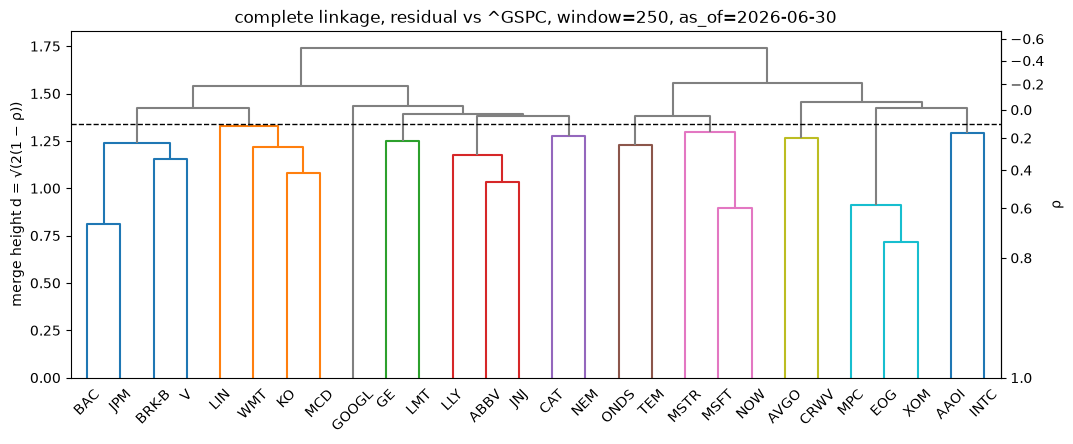

,score,predicted_return,cluster
ticker,,,
V,-0.245390,0.0,A
BRK-B,-0.499922,0.0,A
JPM,-0.546577,0.0,A
BAC,-0.582969,0.0,A
KO,0.059416,0.0,B
LIN,-0.315449,0.0,B
WMT,-0.461495,0.0,B
MCD,-0.509896,0.0,B
LLY,1.955943,0.0,C


In [15]:
cp = cfg.cluster
CLUSTER = pf.cluster.hierarchical(prices, benchmarks, AS_OF, **asdict(cp))
Z, leaves = pf.cluster.linkage_tree(prices, benchmarks, AS_OF, cp.window, cp.remove_market, cp.mkt, cp.method)
h = np.sqrt(2 * (1 - cp.min_corr))  # cut by min_corr by default

print(f"AS_OF={AS_OF.date()}  {asdict(cp)}")
print(f"{len(leaves)} stocks clustered into {CLUSTER.nunique()} clusters; cut height h = {h:.3f} (ρ ≥ {cp.min_corr})")
print("Clusters:", {k: sorted(v) for k, v in CLUSTER.dropna().groupby(CLUSTER.dropna()).groups.items()})

# Dendrogram: the dashed line is the cut height; stocks joined below it belong to the same cluster; the right axis shows the corresponding correlation ρ = 1 − d²/2
set_link_color_palette([f"C{i}" for i in range(10) if i != 7])  # C7 is gray and can't be told apart from the gray lines above the cut
fig, ax = plt.subplots(figsize=(12, 4.5))
dendrogram(Z, labels=leaves, color_threshold=h, above_threshold_color="grey", ax=ax)
ax.axhline(h, ls="--", c="k", lw=1)
ax.set_ylabel("merge height d = √(2(1 − ρ))")
ax.secondary_yaxis("right", functions=(lambda d: 1 - d**2 / 2, lambda r: np.sqrt(np.clip(2 * (1 - r), 0, None)))).set_ylabel("ρ")
ax.set_title(f"{cp.method} linkage, residual vs {cp.mkt}, window={cp.window}, as_of={AS_OF.date()}")
plt.show()

# Each stock's cluster on AS_OF, alongside its total score
table.assign(cluster=CLUSTER).sort_values(["cluster", "score"], ascending=[True, False])

In [16]:
# Checks (no output if everything passes)
from string import ascii_uppercase

from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform

hier, tree = pf.cluster.hierarchical, pf.cluster.linkage_tree
params = asdict(cp)
t = prices.index.get_loc(AS_OF)

# Hand computation: daily returns in the window → OLS with intercept on mkt (np.polyfit), take residuals → correlation → distance → complete linkage
P_win = prices.iloc[t - cp.window : t + 1]
R = P_win.pct_change(fill_method=None).iloc[1:].dropna(axis=1)
M = benchmarks[cp.mkt].reindex(P_win.index).pct_change(fill_method=None).iloc[1:]
E = R.apply(lambda y: y - np.polyval(np.polyfit(M, y, 1), M))
rho = E.corr()
dist = lambda c: squareform(np.sqrt(np.clip(2 * (1 - c.to_numpy()), 0, None)), checks=False)
assert len(R) == cp.window and leaves == R.columns.tolist()
assert np.allclose(E.T @ M, 0) and np.allclose(E.mean(), 0)  # residuals are orthogonal to the market and have mean 0
assert np.allclose(Z, linkage(dist(rho), "complete"))

# index equals prices.columns; stocks taking part in clustering all have labels, the rest are NaN
assert CLUSTER.index.equals(prices.columns)
assert CLUSTER.notna().equals(prices.columns.to_series().isin(leaves).set_axis(prices.columns))

# complete + min_corr: any two stocks in a cluster have ρ ≥ min_corr; number of clusters = 1 + number of merges with height > h
groups = {k: sorted(v) for k, v in CLUSTER.dropna().groupby(CLUSTER.dropna()).groups.items()}
for g in groups.values():
    assert rho.loc[g, g].to_numpy().min() >= cp.min_corr - 1e-12, g
assert len(groups) == 1 + (Z[:, 2] > h).sum()

# Labels: A, B, … contiguous; in descending cluster size, ties by the alphabetical order of the smallest symbol in the cluster
keys = sorted(groups, key=lambda s: (len(s), s))
assert keys == list(ascii_uppercase[: len(keys)])
assert [(-len(groups[k]), groups[k][0]) for k in keys] == sorted((-len(g), g[0]) for g in groups.values())

# Causality: truncating prices / benchmarks at AS_OF gives the same result as the full sample
pd.testing.assert_series_equal(CLUSTER, hier(prices.loc[:AS_OF], benchmarks.loc[:AS_OF], AS_OF, **params))

# Without removing the market component: use the correlation of daily returns directly; benchmarks are not needed then
raw = {**params, "remove_market": False}
Z_raw, _ = tree(prices, None, AS_OF, cp.window, False, cp.mkt, cp.method)
assert np.allclose(Z_raw, linkage(dist(R.corr()), "complete"))
assert hier(prices, None, AS_OF, **raw).notna().sum() == len(leaves)

# n_clusters: cuts into exactly K clusters; with K = number of participating stocks each stock is its own cluster, and labels go past Z to AA, AB, …
by_k = {**params, "min_corr": None}
assert hier(prices, benchmarks, AS_OF, **{**by_k, "n_clusters": 5}).nunique() == 5
single = hier(prices, benchmarks, AS_OF, **{**by_k, "n_clusters": len(leaves)})
assert single.nunique() == len(leaves) == 31 and set(single) == set(ascii_uppercase) | {"AA", "AB", "AC", "AD", "AE"}
assert hier(prices, benchmarks, AS_OF, **{**by_k, "n_clusters": 1}).eq("A").all()

# The other linkages also run, and only label the stocks taking part in clustering
for m in ["single", "average", "ward"]:
    assert hier(prices, benchmarks, AS_OF, **{**params, "method": m}).notna().sum() == len(leaves), m

# NaN falls only on the problematic stock: TICKER missing one day in the window → only it is NaN
p_gap = prices.copy()
p_gap.loc[prices.index[t - 10], TICKER] = np.nan
c_gap = hier(p_gap, benchmarks, AS_OF, **params)
assert pd.isna(c_gap[TICKER]) and c_gap.drop(TICKER).notna().all()
# Stocks listed fewer than window days are NaN (TEM listed 2024-06-14 and only gets a label after 250 trading days)
early = prices.index[prices.index.get_loc(prices["TEM"].first_valid_index()) + 100]
c_early = hier(prices, benchmarks, early, **params)
assert c_early[["TEM", "CRWV"]].isna().all() and c_early.notna().sum() == 29  # CRWV was not yet listed at this point
# Fewer than window rows before as_of → all NaN; mkt missing values in the window → all NaN
assert hier(prices, benchmarks, prices.index[cp.window - 1], **params).isna().all()
b_gap = benchmarks.copy()
b_gap.loc[prices.index[t - 10], cp.mkt] = np.nan
assert hier(prices, b_gap, AS_OF, **params).isna().all()
# With only 1 participating stock it is "A"
assert hier(prices[[TICKER]], benchmarks, AS_OF, **params).tolist() == ["A"]

# Raises when parameters are out of range
for bad in [{"min_corr": None, "n_clusters": None}, {"min_corr": 0.1, "n_clusters": 5}, {"min_corr": 1.5},
            {"min_corr": None, "n_clusters": 0}, {"method": "centroid"}, {"window": 2}, {"mkt": "not_an_index"}]:
    try:
        hier(prices, benchmarks, AS_OF, **{**params, **bad})
    except ValueError:
        continue
    raise AssertionError(f"should raise: {bad}")
try:
    hier(prices, None, AS_OF, **params)  # remove_market=True but no benchmarks
except ValueError:
    pass
else:
    raise AssertionError("remove_market=True with benchmarks=None should raise")

### 5.2 Stock selection: cluster_cap

`selection.cluster_cap(score, cluster, **cfg.selection.cluster_cap)`: takes the total score $S$ on $t_0$ with NaN removed and the cluster labels $c$ from §5.1, and selects stocks greedily in descending total score.

Let $K$ = `max_per_cluster`, $n_{\min}$ = `min_n`, $n_{\max}$ = `max_n`, $\Delta$ = `max_gap`.
Sort stocks by $S$ descending as $i_1, i_2, \dots$ (ties keep their original order); the selected set $\mathcal{S}$ starts empty; consider each $i_k$ in turn:

1. $|\mathcal{S}| = n_{\max}$: stop.
2. $\mathcal{S}$ already has $K$ stocks in the same cluster as $i_k$: skip $i_k$ and consider the next one.
3. $|\mathcal{S}| \ge n_{\min}$ and $S_{\text{last}} - S_{i_k} > \Delta$ ($S_{\text{last}}$ is the total score of the last selected stock): stop; no later stocks are considered.
4. Otherwise add $i_k$ to $\mathcal{S}$.

- The gap is measured against **the previous selected stock**; stocks skipped by the cluster cap do not count; gaps are not checked until $n_{\min}$ stocks are selected, and the cluster cap always applies; a gap exactly equal to $\Delta$ does not stop.
- The result is in descending total score, $|\mathcal{S}| \le n_{\max}$, at most $K$ per cluster; with too few available stocks or binding cluster caps it can be fewer than $n_{\min}$, until exhausted.
- Raises when a stock with a total score has a NaN cluster (missing prices in the clustering window); try reducing `cfg.cluster.window`.
- Defaults $K = 2$, $n_{\min} = 3$, $n_{\max} = 6$, $\Delta = 100$ (i.e. no limit; the actual value is to be decided with backtest support).

In [17]:
sp = cfg.selection.cluster_cap
SELECTED = pf.selection.SELECTORS[cfg.selection.method](S.dropna(), CLUSTER, **asdict(sp))

print(f"AS_OF={AS_OF.date()}  {cfg.selection.method}  {asdict(sp)}")
print(f"{S.notna().sum()} stocks have a total score, {len(SELECTED)} selected: {SELECTED}")

# All stocks in descending total score: cluster and whether selected
ranked = table.assign(cluster=CLUSTER).dropna(subset=["score"]).sort_values("score", ascending=False, kind="stable")
ranked.assign(selected=ranked.index.isin(SELECTED))

AS_OF=2026-06-30  cluster_cap  {'max_per_cluster': 2, 'min_n': 3, 'max_n': 6, 'max_gap': 100.0}
27 stocks have a total score, 6 selected: ['ONDS', 'GOOGL', 'LLY', 'CAT', 'NEM', 'AAOI']


,score,predicted_return,cluster,selected
ticker,,,,
ONDS,2.043239,0.0,J,True
GOOGL,1.956500,0.0,K,True
LLY,1.955943,0.0,C,True
CAT,1.904620,0.0,H,True
NEM,1.676659,0.0,H,True
AAOI,1.591932,0.0,F,True
AVGO,1.531158,0.0,G,False
JNJ,0.590505,0.0,C,False
GE,0.269677,0.0,I,False


In [18]:
# Checks (no output if everything passes)
sel = pf.selection.cluster_cap
avail = S.dropna()
p = asdict(sp)

# On AS_OF: descending total score; at most max_n stocks, at most max_per_cluster per cluster
assert avail[SELECTED].is_monotonic_decreasing and len(SELECTED) <= sp.max_n
assert CLUSTER[SELECTED].value_counts().max() <= sp.max_per_cluster

# With max_gap unlimited, matches the hand computation "descending total score, skip full clusters, fill up to max_n"
def hand(score, cluster, K, n_max):
    out = []
    for t in score.sort_values(ascending=False, kind="stable").index:
        if len(out) < n_max and (cluster[out] == cluster[t]).sum() < K:
            out.append(t)
    return out

assert SELECTED == hand(avail, CLUSTER, sp.max_per_cluster, sp.max_n)
# When the cluster cap doesn't bind (K ≥ max_n), it reduces to the top max_n by total score
assert sel(avail, CLUSTER, **{**p, "max_per_cluster": sp.max_n}) == avail.nlargest(sp.max_n).index.tolist()

# Synthetic data: a, b, c, g are all in cluster A
s = pd.Series([5.0, 4.5, 4.0, 3.0, 2.5, 1.0, 0.5], index=list("abcdefg"))
c = pd.Series(["A", "A", "A", "B", "C", "D", "A"], index=s.index)
base = dict(max_per_cluster=2, min_n=3, max_n=6, max_gap=100.0)
# Cluster cap: after a and b fill cluster A, c and g are skipped; with fewer stocks than max_n, select until exhausted
assert sel(s, c, **base) == ["a", "b", "d", "e", "f"]
assert sel(s, c, **{**base, "max_per_cluster": 1}) == ["a", "d", "e", "f"]
# min_n: the first 3 are not checked for gaps (b → d differ by 1.5); e is 0.5 below d and is selected; f is 1.5 > 1 below e, so stop
assert sel(s, c, **{**base, "max_gap": 1.0}) == ["a", "b", "d", "e"]
# The gap is measured against the previous selected stock b (4.5 − 3.0 = 1.5 > 1.25, stop), not against the adjacent-ranked but skipped c (4.0 − 3.0 = 1.0)
assert sel(s, c, **{**base, "min_n": 2, "max_gap": 1.25}) == ["a", "b"]
# A gap exactly equal to max_gap does not stop
assert sel(s, c, **{**base, "min_n": 1, "max_gap": 0.5}) == ["a", "b"]
# max_n: stop once full
assert sel(s, c, **{**base, "max_n": 3}) == ["a", "b", "d"]
# Cluster cap leaves fewer than min_n: when all are in the same cluster only K are selected
assert sel(s, pd.Series("A", index=s.index), **base) == ["a", "b"]
# Ties go to whichever appears first in score; empty score returns an empty list
assert sel(pd.Series([1.0, 2.0, 2.0], index=list("xyz")), pd.Series(list("ABC"), index=list("xyz")), **base) == ["y", "z", "x"]
assert sel(pd.Series(dtype=float), c, **base) == []

# Raises when a stock with a total score has a NaN or missing cluster, or parameters are out of range
for args in [(s, c.where(c.index != "f"), base), (s, c.drop("g"), base),
             (s, c, {**base, "max_per_cluster": 0}), (s, c, {**base, "min_n": 0}), (s, c, {**base, "min_n": 7}),
             (s, c, {**base, "max_n": 0}), (s, c, {**base, "max_gap": -1.0})]:
    try:
        sel(args[0], args[1], **args[2])
    except ValueError:
        continue
    raise AssertionError(f"should raise: {args[2]}")

## 6. Weights: robust MVO

Inputs: the selected stock set $\mathcal{S}$, the predicted returns $\mu$ and prediction standard errors $u$ from the same KNN run, and close prices on and before $t_0$.

$$
\Sigma = H\hat\Sigma^{\mathrm{LW}}_{\mathrm{daily}},
\qquad
\Omega = \operatorname{diag}(u_1^2,\dots,u_n^2)
$$

$$
\max_w\; \mu^\top w
-\kappa\sqrt{w^\top\Omega w},
\qquad
\mathbf 1^\top w + w_{\mathrm{cash}}=1,\quad 0\le w_{\mathrm{cash}}\le1,\quad
\sqrt{w^\top\Sigma w}\le \sigma_{\max},\quad
0\le w_i\le w_{\max}
$$

$\Sigma$ describes asset return risk; $\Omega$ describes KNN's estimation error of $\mu$. The two do not double count. Because the stocks' neighbor dates are not fully aligned, the first version uses only the diagonal variance of the KNN uncertainty.

`CASH` has zero return, prediction uncertainty and volatility; $w_{\mathrm{cash}} = 1 - \sum_i w_i$, not bound by the single-stock cap $w_{\max}$.


In [ ]:
wp = cfg.weights.robust_mvo
H = cfg.task.holding_days
params = dict(lookback=wp.lookback, horizon=H, kappa=wp.kappa, max_volatility=wp.max_volatility, lower=wp.lower, upper=wp.upper)
robust_mvo = pf.weights.WEIGHTERS[cfg.weights.method]

# SELECTED is the selection result of §5.2; μ and u come from the same KNN run in §3.2
mu = table["predicted_return"]
u = details.uncertainty
w = robust_mvo(prices, mu, u, SELECTED, AS_OF, **params)

t = prices.index.get_loc(AS_OF)
r_win = returns.iloc[t - wp.lookback + 1 : t + 1][SELECTED]
sigma_H = np.sqrt(H * np.diag(LedoitWolf().fit(r_win.to_numpy()).covariance_))
print(f"AS_OF={AS_OF.date()}  window {r_win.index[0].date()} → {r_win.index[-1].date()}  {params}")
display(pd.DataFrame({"mu": mu.reindex(w.index), "uncertainty": u.reindex(w.index),
                      "sigma_H": pd.Series(sigma_H, index=SELECTED).reindex(w.index),
                      "w": w}).sort_values("w", ascending=False))

# κ sensitivity comparison with synthetic μ; u still uses the prediction standard errors from the same KNN run
mu_syn = pd.Series(np.linspace(-0.03, 0.05, len(prices.columns)), index=prices.columns)
by_kappa = pd.DataFrame({
    k: robust_mvo(prices, mu_syn, u, SELECTED, AS_OF, **{**params, "kappa": k})
    for k in [0.0, 0.5, 1.0, 2.0, 4.0]
})
by_kappa.loc["effective number of holdings"] = 1 / (by_kappa ** 2).sum()
by_kappa.round(3).rename_axis(columns="kappa")

In [ ]:
# Checks (no output if everything passes)
from scipy.optimize import minimize
from sklearn.covariance import ledoit_wolf

tol = 1e-6
CASH = pf.weights.CASH
Sig = H * ledoit_wolf(r_win.to_numpy())[0]

def objective(x, m, uncertainty, kappa):
    return m @ x - kappa * np.linalg.norm(uncertainty * x)

risky_w = w.loc[SELECTED].to_numpy()
assert list(w.index) == SELECTED + [CASH]
assert abs(w.sum() - 1) < tol and 0 <= w[CASH] <= 1 + tol
assert (risky_w >= wp.lower).all() and (risky_w <= wp.upper).all() and w[CASH] >= 0
# Values within 1e-8 of a bound are set to the bound, leaving no fake positions like 5e-10
assert ((risky_w == wp.lower) | (risky_w - wp.lower >= 1e-8)).all()
assert np.sqrt(risky_w @ Sig @ risky_w) <= wp.max_volatility + tol

m_syn = mu_syn[SELECTED].to_numpy()
u_sel = u[SELECTED].to_numpy()
for m in (mu[SELECTED].to_numpy(), m_syn):
    result = robust_mvo(prices, pd.Series(m, index=SELECTED), u, SELECTED, AS_OF, **params)
    x = result.loc[SELECTED].to_numpy()
    ref = minimize(
        lambda v: -objective(v, m, u_sel, wp.kappa),
        np.full(len(m), min(0.5 / len(m), wp.upper / 2)),
        method="SLSQP",
        bounds=[(wp.lower, wp.upper)] * len(m),
        constraints=[
            {"type": "ineq", "fun": lambda v: 1 - v.sum()},
            {"type": "ineq", "fun": lambda v: wp.max_volatility**2 - v @ Sig @ v},
        ],
        options={"ftol": 1e-12, "maxiter": 1000},
    )
    assert ref.success, ref.message
    assert np.allclose(x, ref.x, atol=1e-4), (x, ref.x)
    assert np.isclose(result[CASH], 1 - x.sum(), atol=tol)

# When all predicted returns are strongly negative, it holds almost entirely cash
all_cash = robust_mvo(
    prices, pd.Series(-1.0, index=prices.columns), u, SELECTED, AS_OF, **params
)
assert all_cash[CASH] > 1 - tol

# The risk budget uses the H-day holding-period portfolio volatility of the stock part (CASH volatility is 0)
portfolio_volatility = np.sqrt(risky_w @ Sig @ risky_w)
assert portfolio_volatility <= wp.max_volatility + tol

# Causality
pd.testing.assert_series_equal(
    w, robust_mvo(prices.loc[:AS_OF], mu, u, SELECTED, AS_OF, **params)
)

# Raises on invalid inputs or constraints
bad_calls = [
    (mu.where(mu.index != SELECTED[0]), u, SELECTED, AS_OF, params),
    (mu, u.where(u.index != SELECTED[0]), SELECTED, AS_OF, params),
    (mu, u, SELECTED, AS_OF, {**params, "lower": -0.1}),
    (mu, u, SELECTED, AS_OF, {**params, "kappa": -0.1}),
    (mu, u, SELECTED, AS_OF, {**params, "max_volatility": 0.0}),
    (mu, u, [], AS_OF, params),
    (mu, u, SELECTED[:1] + [CASH], AS_OF, params),
    (mu, u, SELECTED, AS_OF, {**params, "lower": 1 / len(SELECTED) + 0.01, "upper": 1.0}),
]
for m, uncertainty, sel, date, p in bad_calls:
    try:
        robust_mvo(prices, m, uncertainty, sel, date, **p)
    except ValueError:
        continue
    raise AssertionError(f"should raise: selected={sel}, as_of={date.date()}, params={p}")


## 7. Holding period and rolling backtest

### 7.1 Holding-period return: buy and hold, no rebalancing

`backtest.holding_returns(prices, w, as_of, H)`. Build the position at the $t_0$ close according to $w$; the portfolio NAV is:

$$
V_{t_0} = 1, \qquad
V_t = w_{\mathrm{cash}} + \sum_i w_i \frac{P_{i,t}}{P_{i,t_0}}, \qquad t = t_0+1, \dots, t_0+H
$$

Portfolio daily returns use the **drifted** weights, not the fixed $w$:

$$
r^{p}_t = \frac{V_t}{V_{t-1}} - 1 = \sum_i \tilde{w}_{i,t-1}\, r_{i,t}, \qquad
\tilde{w}_{i,t-1} = \frac{w_i\, P_{i,t-1} / P_{i,t_0}}{V_{t-1}}
$$

In general $r^p_t \ne \sum_i w_i r_{i,t}$. Period return $R = \prod_t (1 + r^p_t) - 1 = V_{t_0+H} - 1$.

- The output index is the $H$ trading days after $t_0$ (by row position, not calendar days); only prices in rows $t_0 \dots t_0+H$ are used.
- A held stock missing a price on some day: that day's $V$ is NaN, and $r^p$ is NaN on that day and the next, without renormalizing over the remaining stocks.
- Raises when there are fewer than $H$ rows after $t_0$.

In [ ]:
H = cfg.task.holding_days
r_p = pf.backtest.holding_returns(prices, w, AS_OF, H)

t = prices.index.get_loc(AS_OF)
CASH = pf.weights.CASH
risky_w = w.drop(CASH)
P_hold = prices.iloc[t : t + H + 1][risky_w.index]  # t0 … t0+H
growth = P_hold / P_hold.iloc[0]
V = w[CASH] + growth @ risky_w
print(f"AS_OF={AS_OF.date()}  holding {r_p.index[0].date()} → {r_p.index[-1].date()} ({len(r_p)} days)  period return {(1 + r_p).prod() - 1:.4%}  CASH={w[CASH]:.2%}")

# Each selected stock and CASH: entry weight, holding-period return, drifted weight at period end
asset_growth = pd.concat([growth.iloc[-1], pd.Series({CASH: 1.0})])
display(pd.DataFrame({
    "w": w,
    "R_i": asset_growth - 1,
    "w_end": w * asset_growth / V.iloc[-1],
}))
# Daily: portfolio daily return r^p and NAV V
pd.DataFrame({"r_p": r_p, "V": V.iloc[1:]})


In [ ]:
# Checks (no output if everything passes)
r_i = P_hold.pct_change(fill_method=None).iloc[1:]

# Matches the drifted-weight formula day by day; drifted weights of stocks and CASH sum to 1
w_drift = growth.mul(risky_w, axis=1).div(V, axis=0).shift(1).iloc[1:]
cash_drift = (w[CASH] / V).shift(1).iloc[1:]
assert np.allclose(r_p, (w_drift * r_i).sum(axis=1))
assert np.allclose(w_drift.sum(axis=1) + cash_drift, 1)

# Period return = V_{t0+H} − 1; H rows starting from the next trading day
assert np.isclose((1 + r_p).prod() - 1, V.iloc[-1] - 1)
assert len(r_p) == H and r_p.index[0] == prices.index[t + 1] and r_p.index[-1] == prices.index[t + H]

# An all-cash portfolio has zero return
all_cash_return = pf.backtest.holding_returns(prices, pd.Series({CASH: 1.0}), AS_OF, H)
assert np.allclose(all_cash_return, 0)

# Only rows t0 … t0+H are used: changing or deleting later prices leaves the result unchanged
shocked = prices.copy()
shocked.iloc[t + H + 1 :] *= 2
pd.testing.assert_series_equal(r_p, pf.backtest.holding_returns(shocked, w, AS_OF, H))
pd.testing.assert_series_equal(r_p, pf.backtest.holding_returns(prices.iloc[: t + H + 1], w, AS_OF, H))

# A held stock missing one day's price: NaN on that day and the next, other days unchanged
k = 10
holed = prices.copy()
holed.loc[prices.index[t + k], risky_w.index[0]] = np.nan
r_h = pf.backtest.holding_returns(holed, w, AS_OF, H)
hole = r_p.index[[k - 1, k]]
assert r_h[hole].isna().all() and r_h.drop(hole).notna().all()
pd.testing.assert_series_equal(r_h.drop(hole), r_p.drop(hole))

# Works with exactly H rows after; raises with fewer than H rows, H < 1, or as_of not a trading day
assert pf.backtest.holding_returns(prices, w, prices.index[-H - 1], H).notna().all()
for d, h in [(prices.index[-H], H), (AS_OF, 0), (pd.Timestamp("2026-07-04"), H)]:
    try:
        pf.backtest.holding_returns(prices, w, d, h)
    except ValueError:
        continue
    raise AssertionError(f"should raise: as_of={d.date()}, horizon={h}")


### 7.2 Rolling rule and single-period decision

**Rolling rule** `backtest.as_of_dates(index, start, end, step, H)` (parameters are `start`, `end`, `step` of the C-class `RunSpec`):
$a$ is the row number of the first trading day $\ge$ `start`, $e$ is the row number of the last trading day $\le$ `end`,

$$
\{\,t_k = a + k \cdot \text{step} \;:\; k = 0, 1, \dots,\ \ t_k + H \le e \,\}
$$

i.e. every as_of and its holding period fall within [start, end]. When step = H periods are joined end to end into one portfolio daily return series;
when step < H periods overlap, `BacktestResult.returns` is None, and there are only per-period returns.

**Single-period decision** `backtest.decide(prices, fundamentals, benchmarks, as_of, cfg)`: truncate (prices and benchmarks $\le t_0$, fundamentals `ann_date` $< t_0$)
→ §3 factors → §4 scoring → §5 clustering and selection → §6 weights. `run_backtest` calls `decide` and §7.1 for each $t_k$.
Raises `ValueError` when `factor_weights` contains an unregistered factor, or not a single stock can be selected (as_of too early, every stock is missing some factor).

In [ ]:
RUN = pf.config.RunSpec(start="2025-01-01", end="2025-06-24", step=H, label="debug", note="")  # three periods for checking the normal flow; the decision on 2025-10-17 raises because TEM's uncertainty is missing
dates = pf.backtest.as_of_dates(prices.index, RUN.start, RUN.end, RUN.step, H)
print(f"{RUN}  →  {len(dates)} as_of dates: {[d.date().isoformat() for d in dates]}")

# One complete decision on AS_OF: total scores and weights of the selected stocks
table_d, w_d = pf.backtest.decide(prices, fundamentals, benchmarks, AS_OF, cfg)
table_d.reindex(w_d.index)[["score", "cluster"]].assign(w=w_d)

In [ ]:
# Checks (no output if everything passes)
as_of_dates = pf.backtest.as_of_dates
idx = prices.index

# The first as_of is the first trading day ≥ start; adjacent ones are step rows apart; the last period does not go past end, and one more would
pos = idx.get_indexer(dates)
e = idx.get_loc(idx[idx <= pd.Timestamp(RUN.end)][-1])
assert dates[0] == idx[idx >= pd.Timestamp(RUN.start)][0]
assert (np.diff(pos) == RUN.step).all()
assert pos[-1] + H <= e < pos[-1] + RUN.step + H
# With step = 1 all feasible as_of dates are taken
assert len(as_of_dates(idx, RUN.start, RUN.end, 1, H)) == e - pos[0] - H + 1

# Raises when step < 1, H < 1, start > end, or none can be taken; also raises when end falls within the first H rows of the data or before the data (must not wrap around to dates at the end)
early = [(str(idx[0].date()), str(idx[H - 1].date()), H, H), ("2010-01-01", "2010-06-01", H, H)]
for args in [(RUN.start, RUN.end, 0, H), (RUN.start, RUN.end, H, 0), (RUN.end, RUN.start, H, H), (RUN.end, RUN.end, H, H), *early]:
    try:
        as_of_dates(idx, *args)
    except ValueError:
        continue
    raise AssertionError(f"should raise: {args}")

# decide matches the step-by-step calls in §3–§6: prediction, uncertainty and neighbor count from the same KNN run, plus cluster labels.
pd.testing.assert_frame_equal(table_d, table.assign(
    prediction_uncertainty=details.uncertainty,
    knn_neighbor_count=details.neighbor_count,
    cluster=CLUSTER,
))
pd.testing.assert_series_equal(w_d, w)
assert list(w_d.index) == SELECTED + [pf.weights.CASH]

# Causality: passing the full sample gives the same result as passing data truncated at AS_OF; changing fundamentals announced on or after AS_OF leaves the result unchanged
f_cut = fundamentals[fundamentals["ann_date"] < AS_OF]
for f_in, p_in, b_in in [(f_cut, prices.loc[:AS_OF], benchmarks.loc[:AS_OF]),
                         (fundamentals.assign(value=fundamentals["value"].where(fundamentals["ann_date"] < AS_OF, 1.0)), prices, benchmarks)]:
    table_c, w_c = pf.backtest.decide(p_in, f_in, b_in, AS_OF, cfg)
    pd.testing.assert_frame_equal(table_c, table_d)
    pd.testing.assert_series_equal(w_c, w_d)

# decide raises: factor_weights contains an unregistered factor; as_of too early, no stock has a total score
cfg_typo = pf.config.Config()
cfg_typo.factor_weights["momentun"] = 1.0
for cfg_in, as_of_in in [(cfg_typo, AS_OF), (cfg, idx[H])]:
    try:
        pf.backtest.decide(prices, fundamentals, benchmarks, as_of_in, cfg_in)
    except ValueError:
        continue
    raise AssertionError(f"should raise: as_of={as_of_in.date()}, factor_weights={cfg_in.factor_weights}")

# With only one neighbor KNN cannot estimate uncertainty; keep the new MVO's raising behavior instead of silently filtering selected stocks.
try:
    pf.backtest.decide(prices, fundamentals, benchmarks, pd.Timestamp("2025-10-17"), cfg)
except ValueError as exc:
    assert "TEM" in str(exc) and "prediction uncertainty" in str(exc)
else:
    raise AssertionError("missing prediction uncertainty for TEM should raise")

## 8. Evaluation metrics and run records

### 8.1 Evaluation metrics

The holding period of one period $t_0$ (as_of) is the $H$ trading days after it, $d = 1,\dots,H$. Portfolio $X$ has daily returns $r^X_d$ and NAV $V^X_0 = 1$, $V^X_d = \prod_{j\le d}(1 + r^X_j)$.
Strategy S's daily returns are taken from `BacktestResult.daily`, the baselines from `baseline_daily` / `random_daily`.

**Risk-free rate** `BacktestResult.rf_daily` (`backtest.rf_daily`):

$$
rf_d = \mathrm{IRX}^{\text{eff}}_d / 100 / A
$$

where $\mathrm{IRX}^{\text{eff}}_d$ is the most recent non-NaN ^IRX (13-week T-bill yield, annualized percent) with date ≤ $d$. On days when the bond market is closed but the stock market is open, the previous value is used;
NaN when there is no value before that. When benchmarks has no `EvalSpec.risk_free` column, `run_backtest` raises `ValueError`; no constant or 0 is substituted.

**Baseline portfolios** (`backtest.baseline_returns`, weights built by `baselines`): buy and hold, fully invested; weights use only data with date ≤ $t_0$, and daily returns are all computed with `holding_returns` from §7.1.
sel($t_0$) is the set of stocks selected by the strategy (including those with weight 0), $k$ is their number; U($t_0$) is all stocks with a close on $t_0$ (alphabetical). Parameters come from the B-class `EvalSpec` (`cfg.task.eval`).

| Key | Construction |
| --- | --- |
| `gspc` | ^GSPC with weight 1; reindexed to price dates first |
| `ew_pool` | U($t_0$) equally weighted |
| `ew_sel` | sel($t_0$) equally weighted |
| `mom` | The top `mom_k` stocks by `momentum(lookback=mom_lookback, skip=mom_skip)` among those with non-NaN values, equally weighted, ties alphabetical; NaN for the period when fewer than `mom_k` stocks are available |
| `nvda` | NVDA alone, for reference only; NaN when there is no price at $t_0$ |
| `rand` | Draw $k$ stocks from U($t_0$) without replacement, equally weighted, `n_random` portfolios in total; generator `default_rng([random_seed, YYYYMMDD(t0)])` |

**Per-period metrics** `metrics.period_table(result, cfg)`, with column names `<metric>.<subject>`. For S and each deterministic baseline (ddof = 1):

$$
\text{ret} = V_H - 1,\qquad
\text{vol} = \mathrm{std}(r_d)\sqrt{A},\qquad
\text{sharpe} = \frac{\mathrm{mean}(r_d - rf_d)}{\mathrm{std}(r_d)}\sqrt{A},\qquad
\text{mdd} = \max_{0\le d\le H}\Bigl(1 - \frac{V_d}{\max_{0\le j\le d} V_j}\Bigr)
$$

S only: OLS with intercept over $d = 1,\dots,H$ of $\;r^S_d - rf_d = a + \beta\,(r^M_d - rf_d) + \varepsilon_d$ (M is ^GSPC), `alpha` $= a\cdot A$; `n_sel` $= k$; `w_cash` is the CASH weight at entry.
Random portfolio ranks ($X \in \{S,\ \text{ew\_sel}\}$, compared against the same set of random portfolios):

$$
\text{p\_ret}_X = 100\cdot\#\{i : \text{ret}_i < \text{ret}_X\} / n_{\text{random}}
$$

`p_sharpe` likewise. Relative metrics $\text{er}_b = \text{ret}_S - \text{ret}_b$, $\text{dsr}_b = \text{sharpe}_S - \text{sharpe}_b$, $\text{dmdd}_b = \text{mdd}_S - \text{mdd}_b$ (positive means the strategy's drawdown is deeper) are computed from the per-period detail in the summary.

**NaN**: if any daily return of a portfolio is NaN, all its metrics for that period and the relative metrics and ranks involving it are NaN; if $rf_d$ is NaN on any day of the holding period, sharpe of all portfolios and beta, alpha, dsr, p_sharpe are NaN;
when the strategy is all cash ($\mathrm{std}(r^S_d) = 0$), sharpe.S, all dsr for that period and p_sharpe.S are NaN, and it counts toward `n_cash_only`. In that case ret, vol, mdd are 0; beta and alpha are regressed as usual,
$\beta \approx 0$, $\text{alpha} \approx -\mathrm{mean}(rf_d)\cdot A$ (only approximate when rf varies day to day; the check uses a tolerance of 1e-4).

**Cross-period summary** `metrics.evaluate(result, cfg)`: a flat `dict` keyed by `metrics.metric_keys(cfg)`, formatted `<metric>.<subject>.<statistic>`, 128 by default.

| Metric | Subject | Statistic |
| --- | --- | --- |
| ret, vol, sharpe, mdd | S | mean, median, p10, p90 |
| er, dsr, dmdd | gspc, ew_pool, ew_sel, mom, nvda | mean, median, p10, p90, win, se |
| beta, alpha | S | median, p10, p90 |
| p_ret, p_sharpe | S, ew_sel | mean, median, win |
| n_sel, w_cash | S | mean |

Plus the count keys `n_periods` and `n_cash_only`. p10 / p90 are `np.quantile` (linear), with quantiles taken from `EvalSpec.quantiles`;
win: the number of periods with value > 0 for er and dsr, value < 0 for dmdd, value > 50 for p_ret and p_sharpe, / $n$ (strict inequality; ties are not wins);
se $= \mathrm{std}(\text{ddof}=1)/\sqrt{n}$, computed only when periods do not overlap (each period's end ≤ the next as_of), otherwise NaN. $n$ is the number of periods included in the statistic.
A statistic is NaN if any period is NaN; the only exception is that `sharpe.S.*`, `dsr.*.*`, `p_sharpe.S.*` skip all-cash periods, reducing $n$ accordingly.

The first cell below shows the per-period metrics of S and each baseline for the single `AS_OF` period, plus the per-period detail and summary of the three-period short range from §7.2. **Run only after ^IRX has been added to benchmark.csv**, otherwise `run_backtest` raises.

In [ ]:
i0 = prices.index.get_loc(AS_OF)
RUN_1 = pf.config.RunSpec(start=str(AS_OF.date()), end=str(prices.index[i0 + H].date()), step=H, label="debug_1", note="")  # only the single AS_OF period
RES_1 = pf.backtest.run_backtest(prices, fundamentals, benchmarks, cfg, RUN_1)
PT_1 = pf.metrics.period_table(RES_1, cfg)
KEYS = pf.backtest.baseline_keys(cfg.task.eval)  # keys of the deterministic baselines: gspc, ew_pool, ew_sel, mom, nvda

# The AS_OF period: absolute metrics of S and each baseline, plus S's regression, count, cash and random portfolio ranks
row = PT_1.loc[AS_OF]
display(pd.DataFrame({x: {m: row[f"{m}.{x}"] for m in ("ret", "vol", "sharpe", "mdd")} for x in ["S", *KEYS]}).T)
display(row[["beta.S", "alpha.S", "n_sel.S", "w_cash.S", "p_ret.S", "p_sharpe.S", "p_ret.ew_sel", "p_sharpe.ew_sel"]].to_frame(AS_OF.date()))

RES = pf.backtest.run_backtest(prices, fundamentals, benchmarks, cfg, RUN)  # the short-range rolling rule from §7.2
PT = pf.metrics.period_table(RES, cfg)
METRICS = pf.metrics.evaluate(RES, cfg)
display(PT.T)
pd.Series(METRICS, name="metrics").to_frame()

In [ ]:
# Checks (no output if everything passes)
A = cfg.task.periods_per_year
EV = cfg.task.eval
RF = EV.risk_free
CASH = pf.weights.CASH
M_KEY = KEYS[list(EV.index_baselines).index(cfg.data.benchmark)]
win = prices.index[i0 + 1 : i0 + H + 1]
assert list(METRICS) == pf.metrics.metric_keys(cfg) and len(METRICS) == 128
assert METRICS["n_periods"] == len(dates) == RES.daily.shape[1] and METRICS["n_cash_only"] == 0
assert (PT["ret.S"] == RES.periods["period_return"]).all()  # S's ret is period_return

# Independence: baselines do not affect decisions; the backtest's strategy weights and daily returns equal per-period decide + holding_returns
for a in RES.periods.index:
    _, w_a = pf.backtest.decide(prices, fundamentals, benchmarks, a, cfg)
    pd.testing.assert_series_equal(RES.weights.loc[a].dropna().sort_index(), w_a.sort_index(), check_names=False)
    r_a = pf.backtest.holding_returns(prices, w_a, a, H)
    pd.testing.assert_series_equal(RES.daily.loc[r_a.index, a], r_a, check_names=False)

# Hand-compute ret, vol, sharpe, mdd of S and each baseline for the AS_OF period; compare beta and alpha with np.linalg.lstsq
rf_win = RES_1.rf_daily[win].to_numpy()
def hand(r):
    r = np.asarray(r, dtype=float)
    v = np.concatenate([[1.0], np.cumprod(1 + r)])
    sd = r.std(ddof=1)
    mdd = max(1 - v[d] / v[: d + 1].max() for d in range(len(v)))
    return {"ret": v[-1] - 1, "vol": sd * np.sqrt(A), "sharpe": (r - rf_win).mean() / sd * np.sqrt(A), "mdd": mdd}
port = {"S": RES_1.daily.loc[win, AS_OF], **{b: RES_1.baseline_daily[b].loc[win, AS_OF] for b in KEYS}}
for x, r in port.items():
    for m, val in hand(r).items():
        assert np.isclose(PT_1.loc[AS_OF, f"{m}.{x}"], val, rtol=1e-12, atol=1e-15, equal_nan=True), (x, m)
y = port["S"].to_numpy() - rf_win
xm = port[M_KEY].to_numpy() - rf_win
(a_hat, b_hat), *_ = np.linalg.lstsq(np.column_stack([np.ones(H), xm]), y, rcond=None)
assert np.isclose(PT_1.loc[AS_OF, "beta.S"], b_hat) and np.isclose(PT_1.loc[AS_OF, "alpha.S"], a_hat * A)
w1 = RES_1.weights.loc[AS_OF]
sel1 = w1.drop(CASH).dropna().index
assert PT_1.loc[AS_OF, "n_sel.S"] == len(sel1) and PT_1.loc[AS_OF, "w_cash.S"] == w1[CASH]

# Hand-compute baseline daily returns: the index is aligned to price dates, holding-period dates match price dates; ew_pool, ew_sel, nvda are equal-weight buy and hold
P = prices.iloc[i0 : i0 + H + 1]
def bh(cols):
    v = (P[list(cols)] / P[list(cols)].iloc[0]).mean(axis=1)
    return (v / v.shift(1) - 1).iloc[1:]
idx_m = benchmarks[cfg.data.benchmark].reindex(prices.index).iloc[i0 : i0 + H + 1]
mom_v = pf.factors.momentum(prices.loc[:AS_OF], None, AS_OF, EV.mom_lookback, EV.mom_skip).dropna()
top = sorted(mom_v.index, key=lambda t: (-mom_v[t], t))[: EV.mom_k]
for b, r in [(M_KEY, (idx_m / idx_m.shift(1) - 1).iloc[1:]), ("ew_pool", bh(P.columns[P.iloc[0].notna()])),
             ("ew_sel", bh(sel1)), ("mom", bh(top)), *[(t.lower(), bh([t])) for t in EV.reference_tickers]]:
    got = RES_1.baseline_daily[b][AS_OF].dropna()
    assert got.index.equals(win), b
    np.testing.assert_allclose(got.to_numpy(), r.to_numpy(), rtol=0, atol=1e-12, err_msg=b)

# mom's selection matches the ranking of factors.momentum (ties alphabetical); None when fewer than mom_k stocks are available (NaN for the period)
assert pf.baselines.momentum_top(prices.loc[:AS_OF], AS_OF, EV.mom_k, EV.mom_lookback, EV.mom_skip) == top
assert pf.baselines.momentum_top(prices.loc[:AS_OF], AS_OF, len(mom_v) + 1, EV.mom_lookback, EV.mom_skip) is None

# rf_daily: on dates where ^IRX has a value it equals that day's rate / 100 / A; on dates when stocks trade but ^IRX is missing it equals the rate of the previous date with a value / 100 / A
irx = benchmarks[RF].dropna()
assert RES.rf_daily.index.equals(prices.index)
on = prices.index.intersection(irx.index)
assert (RES.rf_daily[on] == irx[on] / 100 / A).all()
gaps = prices.index[(prices.index > irx.index[0]) & ~prices.index.isin(irx.index)]
assert len(gaps) > 0, "no dates where stocks trade but ^IRX is missing; cannot check the effective value"
for d in gaps:
    assert RES.rf_daily[d] == irx[irx.index < d].iloc[-1] / 100 / A, d
assert RES.rf_daily[prices.index < irx.index[0]].isna().all()

# All-cash period: use synthetic weights to make RES's first period all cash (selected stocks weight 0, CASH 1)
a0 = RES.periods.index[0]
d0 = RES.daily.index[RES.daily.index > a0][:H]
w_cash = RES.weights.copy()
w_cash.loc[a0, RES.weights.loc[a0].drop(CASH).dropna().index] = 0.0
w_cash.loc[a0, CASH] = 1.0
daily_cash = RES.daily.copy()
daily_cash.loc[d0, a0] = pf.backtest.holding_returns(prices, w_cash.loc[a0].dropna(), a0, H).to_numpy()
res_cash = replace(RES, daily=daily_cash, weights=w_cash,
                   periods=RES.periods.assign(period_return=RES.periods["period_return"].where(RES.periods.index != a0, 0.0)))
pt_c, ev_c = pf.metrics.period_table(res_cash, cfg), pf.metrics.evaluate(res_cash, cfg)
c = pt_c.loc[a0]
assert np.isnan(c["sharpe.S"]) and np.isnan(c["p_sharpe.S"])
assert c["ret.S"] == c["vol.S"] == c["mdd.S"] == 0
assert np.isclose(c["beta.S"], 0, atol=1e-4) and np.isclose(c["alpha.S"], -RES.rf_daily[d0].mean() * A, atol=1e-4)
assert ev_c["n_cash_only"] == 1
# The exception in §4.3 applies only to sharpe.S.*, dsr.*.*, p_sharpe.S.* (skipping all-cash periods); everything else is included as usual
rest = pt_c.index != a0
assert np.isclose(ev_c["sharpe.S.mean"], pt_c.loc[rest, "sharpe.S"].mean())
assert np.isclose(ev_c["p_sharpe.S.median"], pt_c.loc[rest, "p_sharpe.S"].median())
for b in KEYS:
    assert np.isclose(ev_c[f"dsr.{b}.mean"], (pt_c["sharpe.S"] - pt_c[f"sharpe.{b}"])[rest].mean())
    assert np.isclose(ev_c[f"er.{b}.mean"], (pt_c["ret.S"] - pt_c[f"ret.{b}"]).mean())
for k in ("ret.S.mean", "vol.S.mean", "mdd.S.mean", "p_ret.S.mean", "p_sharpe.ew_sel.mean"):
    assert np.isclose(ev_c[k], pt_c[k.rsplit(".", 1)[0]].mean()), k
assert np.isclose(ev_c["beta.S.median"], pt_c["beta.S"].median())

# Random portfolios: generating twice for the same as_of gives the same result; each portfolio has exactly k distinct stocks, all in U(t0); daily returns equal equal-weight holding_returns
k1 = len(sel1)
draws = pf.baselines.random_draws(prices.loc[:AS_OF], AS_OF, k1, EV.n_random, EV.random_seed)
pd.testing.assert_frame_equal(draws, pf.baselines.random_draws(prices.loc[:AS_OF], AS_OF, k1, EV.n_random, EV.random_seed))
U = set(prices.columns[prices.loc[AS_OF].notna()])
assert set(pf.baselines.pool(prices.loc[:AS_OF], AS_OF)) == U
assert draws.shape == (EV.n_random, k1) and all(len(set(d)) == k1 and set(d) <= U for d in draws.to_numpy())
for i in (0, EV.n_random - 1):
    hr = pf.backtest.holding_returns(prices, pf.baselines.equal_weights(list(draws.loc[i])), AS_OF, H)
    pd.testing.assert_series_equal(RES_1.random_daily[AS_OF][i], hr, check_names=False, rtol=0, atol=1e-14)
# After changing RunSpec.start, draws for shared as_of dates are unchanged
res_shift = pf.backtest.run_backtest(prices, fundamentals, benchmarks, cfg, replace(RUN, start=str(RES.periods.index[1].date())))
for a in res_shift.periods.index:
    pd.testing.assert_frame_equal(res_shift.random_daily[a], RES.random_daily[a])
# S and ew_sel use the same portfolios: replacing S with ew_sel's daily returns gives identical ranks; er, dsr, dmdd are always 0, and ties are not wins
res_eq = replace(RES, daily=RES.baseline_daily["ew_sel"])
pt_eq, ev_eq = pf.metrics.period_table(res_eq, cfg), pf.metrics.evaluate(res_eq, cfg)
assert pt_eq["p_ret.S"].equals(pt_eq["p_ret.ew_sel"]) and pt_eq["p_sharpe.S"].equals(pt_eq["p_sharpe.ew_sel"])
assert all(ev_eq[f"{m}.ew_sel.win"] == 0 for m in ("er", "dsr", "dmdd"))

# Causality: baseline weights built from truncated data equal those built from the full sample
for fn, args in [(pf.baselines.pool, ()), (pf.baselines.momentum_top, (EV.mom_k, EV.mom_lookback, EV.mom_skip)),
                 (pf.baselines.random_draws, (k1, EV.n_random, EV.random_seed))]:
    full, cut = fn(prices, AS_OF, *args), fn(prices.loc[:AS_OF], AS_OF, *args)
    assert full.equals(cut) if isinstance(full, pd.DataFrame) else full == cut, fn.__name__

# When step < H (periods overlap) se is all NaN; when they do not overlap it has values
overlap = pf.backtest.run_backtest(prices, fundamentals, benchmarks, cfg, replace(RUN, step=H // 3))
assert overlap.returns is None
assert all(np.isnan(v) for k, v in pf.metrics.evaluate(overlap, cfg).items() if k.endswith(".se"))
assert not np.isnan(METRICS[f"er.{M_KEY}.se"])

# One day's return NaN in a period: S's metrics and ranks for that period are NaN (except n_sel, w_cash), and summaries are NaN, not skipped
daily_nan = RES.daily.copy()
daily_nan.loc[d0[0], a0] = np.nan
res_nan = replace(RES, daily=daily_nan, periods=RES.periods.assign(
    period_return=RES.periods["period_return"].where(RES.periods.index != a0)))
pt_n, ev_n = pf.metrics.period_table(res_nan, cfg), pf.metrics.evaluate(res_nan, cfg)
assert pt_n.loc[a0, [k for k in pt_n.columns if k.endswith(".S") and k not in ("n_sel.S", "w_cash.S")]].isna().all()
assert pt_n.loc[a0, "p_ret.ew_sel"] == PT.loc[a0, "p_ret.ew_sel"]
assert np.isnan(ev_n["ret.S.mean"]) and np.isnan(ev_n[f"er.{M_KEY}.win"]) and not np.isnan(ev_n["n_sel.S.mean"])
# 0 periods: counts are 0, statistics are NaN
ev_0 = pf.metrics.evaluate(replace(RES, periods=RES.periods.iloc[:0]), cfg)
assert ev_0["n_periods"] == 0 and np.isnan(ev_0["ret.S.mean"])

# When the evaluation setup does not match the data, run_backtest raises before deciding: missing risk-free rate column (no constant substituted), index_baselines lacking the market index, etc.
bad = [pf.config.Config(task=pf.config.TaskSpec(eval=pf.config.EvalSpec(**kw))) for kw in (
    {"index_baselines": ("^IXIC",)}, {"index_baselines": ("^GSPC", RF)}, {"reference_tickers": ("XYZ",)},
    {"mom_k": 0}, {"n_random": 0}, {"quantiles": (0.9, 0.1)})]
for b_in, cfg_in in [(benchmarks.drop(columns=RF), cfg), (None, cfg), *[(benchmarks, c_) for c_ in bad]]:
    try:
        pf.backtest.run_backtest(prices, fundamentals, b_in, cfg_in, RUN)
    except ValueError:
        continue
    raise AssertionError(f"should raise: {cfg_in.task.eval}")

### 8.2 Run records

`metrics.save_run(cfg, run, result, metrics, runs_dir)` writes one json per run: `<runs_dir>/<YYYYMMDD_HHMMSS>_<label>_<4-char random string>.json`
(`: * ? " < > | / \` and whitespace in the label are replaced by `_`, then leading/trailing dots and underscores are stripped; the label is required, and if it is empty after processing, constructing `RunSpec` raises `ValueError`;
if it is changed to an empty label after construction, `save_run` raises. The random string is 4 lowercase hex characters, so records from several people with the same label in the same second do not clash). For real runs `runs_dir` is `config.RUNS_DIR` (`outputs/runs/`).

| Section | Contents |
| --- | --- |
| `meta` | Save time (local time), git commit (`"unknown"` if unavailable), original label, note |
| `run` | Rolling rule: start, end, step; together with label and note in meta it restores RunSpec |
| `config` | Full `Config`, nested as dataclasses |
| `metrics` | Output of `evaluate(result, cfg)` |
| `periods` | as_of → last day of the holding period `end`, period return `period_return`, the `period_table` columns except `ret.S` (§8.1), entry weights `weights` (selected stocks only) |

Only things that cannot be recomputed are stored: portfolio daily returns are not stored but recomputed from the weights via `holding_returns` (§7.1) using the same price data (rounding error from floating-point summation order is allowed); baseline and random portfolio daily returns are not stored either, and are recomputed from prices, weights and the `EvalSpec` seed. NaN is stored as `null`. Metrics missing from old records are read as NaN by `load_runs`.

`metrics.load_run(path)` reads back one run, restoring `Config` and `RunSpec` losslessly; `metrics.load_runs(runs_dir)` aggregates all records in the directory into a table
(one row per run, parameters expanded into columns with dots, e.g. `config.factors.momentum.lookback`), without saving a separate summary file.

Below, the read-back parameters, metrics and holdings are compared, then the short-range backtest is rerun with the read-back Config / RunSpec to check that all results match.
The label and note columns in the summary table are `meta.label` and `meta.note`; parameters missing from a run are NaN.
If the file name already exists (same second, same label and same random string), `FileExistsError` is raised and the original file is not overwritten; the directory is not added to `.gitignore`, so real records can be committed.
When recomputing daily returns directly from saved weights, the stock summation order may change, so an absolute error of `1e-14` is allowed; a full rerun with read-back parameters is compared exactly value by value.

In [ ]:
TMP = tempfile.TemporaryDirectory()  # do not write to outputs/
RUNS_TMP = Path(TMP.name)
PATH = pf.metrics.save_run(cfg, RUN, RES, METRICS, RUNS_TMP)
rec = json.loads(PATH.read_text(encoding="utf-8"))
print(PATH.name)
print(json.dumps({**rec, "config": "… (omitted)", "periods": dict(list(rec["periods"].items())[:2])}, ensure_ascii=False, indent=2))

In [ ]:
# Checks (no output if everything passes)
# Read back: Config and RunSpec are identical to before saving; per-period detail and weights equal BacktestResult
r = pf.metrics.load_run(PATH)
assert r.config == cfg and r.run == RUN
assert r.meta == rec["meta"]
assert set(rec) == {"meta", "run", "config", "metrics", "periods"}
assert set(rec["run"]) == {"start", "end", "step"}
assert rec["meta"]["label"] == RUN.label and rec["meta"]["note"] == RUN.note
DETAIL = PT.drop(columns="ret.S").astype("float64")  # ret.S is period_return, not stored twice
assert all(set(p) == {"end", "period_return", "weights", *DETAIL.columns} for p in rec["periods"].values())
pd.testing.assert_frame_equal(r.periods, RES.periods.join(DETAIL))
pd.testing.assert_frame_equal(r.weights, RES.weights.dropna(axis=1, how="all"))
# Metrics: NaN is null in the file and read back as NaN
assert all((v is None) == bool(np.isnan(METRICS[k])) for k, v in rec["metrics"].items())
strict_json = json.dumps(rec, allow_nan=False)  # non-standard NaN / Infinity literals would raise
assert r.metrics.keys() == METRICS.keys()
assert all(r.metrics[k] == METRICS[k] or (np.isnan(r.metrics[k]) and np.isnan(METRICS[k])) for k in METRICS)

# Portfolio daily returns can be recomputed from the stored weights (rounding error from floating-point summation order is allowed)
for as_of in r.periods.index:
    daily_saved = pf.backtest.holding_returns(prices, r.weights.loc[as_of].dropna(), as_of, r.config.task.holding_days)
    pd.testing.assert_series_equal(daily_saved, RES.daily.loc[daily_saved.index, as_of], check_names=False,
                                   rtol=0, atol=1e-14)

# Rerun with the read-back strategy parameters and rolling rule, comparing per-period detail, all weights, daily returns and metrics.
replayed = pf.backtest.run_backtest(prices, fundamentals, benchmarks, r.config, r.run)
for field in ("periods", "weights", "daily"):
    pd.testing.assert_frame_equal(getattr(replayed, field), getattr(RES, field), check_exact=True)
pd.testing.assert_series_equal(replayed.returns, RES.returns, check_exact=True)
assert replayed.baseline_daily.keys() == RES.baseline_daily.keys() and replayed.random_daily.keys() == RES.random_daily.keys()
for k in RES.baseline_daily:
    pd.testing.assert_frame_equal(replayed.baseline_daily[k], RES.baseline_daily[k], check_exact=True)
for a in RES.random_daily:
    pd.testing.assert_frame_equal(replayed.random_daily[a], RES.random_daily[a], check_exact=True)
pd.testing.assert_series_equal(replayed.rf_daily, RES.rf_daily, check_exact=True)
pd.testing.assert_series_equal(pd.Series(pf.metrics.evaluate(replayed, r.config)), pd.Series(METRICS), check_exact=True)

# Changed parameters are also restored losslessly: factors, tree-cut mode, and newly added KNN / MVO parameters
cfg2 = pf.config.Config()
del cfg2.factor_weights["revenue_growth"]
cfg2.cluster.min_corr, cfg2.cluster.n_clusters = None, 5
cfg2.standardize.n = 3.0
cfg2.factors.ret.n_neighbors = 12
cfg2.factors.ret.neighbor_gap = 20
cfg2.weights.robust_mvo.max_volatility = 0.12
run2 = pf.config.RunSpec(start=RUN.start, end=RUN.end, step=RUN.step, label='a: b/c*? 中文', note="中文备注\n第二行：NaN 只是文字")
path2 = pf.metrics.save_run(cfg2, run2, RES, METRICS, RUNS_TMP)
assert pf.metrics.load_run(path2).config == cfg2 and pf.metrics.load_run(path2).run == run2
# Illegal characters and whitespace in the label are replaced by _, while non-ASCII (Chinese) characters are kept; the file name is <timestamp>_<label>_<4 lowercase hex chars>
assert re.fullmatch(r"\d{8}_\d{6}_a_b_c_中文_[0-9a-f]{4}\.json", path2.name)
assert re.fullmatch(rf"\d{{8}}_\d{{6}}_{RUN.label}_[0-9a-f]{{4}}\.json", PATH.name)
# Two saves with the same label in the same second are distinguished by the random string
with patch("pf.metrics.datetime") as clock:
    from datetime import datetime

    clock.now.return_value = datetime(2026, 1, 2, 0, 0, 0)
    with patch("pf.metrics.secrets.token_hex", side_effect=["0000", "ffff"]):
        path3 = pf.metrics.save_run(cfg, RUN, RES, METRICS, RUNS_TMP)
        path3b = pf.metrics.save_run(cfg, RUN, RES, METRICS, RUNS_TMP)
assert (path3.name, path3b.name) == (f"20260102_000000_{RUN.label}_0000.json", f"20260102_000000_{RUN.label}_ffff.json")
path3b.unlink()
# The label is required: constructing RunSpec with an empty string, only whitespace or only illegal characters raises; changing it to an empty label after construction makes save_run raise too
for bad_label in ("", "  ", "._", "::/"):
    try:
        pf.config.RunSpec(start=RUN.start, end=RUN.end, step=RUN.step, label=bad_label, note="")
    except ValueError:
        pass
    else:
        raise AssertionError(f"empty label {bad_label!r} should raise")
emptied = replace(RUN)
emptied.label = ""
try:
    pf.metrics.save_run(cfg, emptied, RES, METRICS, RUNS_TMP)
except ValueError:
    pass
else:
    raise AssertionError("save_run should raise on an empty label")

# Summary: one row per run, ascending by file name; missing parameters are NaN
runs = pf.metrics.load_runs(RUNS_TMP)
assert runs.index.tolist() == sorted(p.stem for p in (PATH, path2, path3))
assert runs.loc[path2.stem, "config.cluster.n_clusters"] == 5 and np.isnan(runs.loc[path2.stem, "config.factor_weights.revenue_growth"])
assert runs.loc[PATH.stem, "config.factor_weights.revenue_growth"] == 1.0
assert [k for k in runs.columns if k.startswith("metrics.")] == [f"metrics.{k}" for k in pf.metrics.metric_keys(cfg)]
assert runs.loc[path2.stem, "meta.label"] == run2.label and runs.loc[path2.stem, "meta.note"] == run2.note
assert runs.loc[PATH.stem, "metrics.ret.S.mean"] == METRICS["ret.S.mean"]
# Empty table when the directory does not exist or has no JSON
assert pf.metrics.load_runs(RUNS_TMP / "nope").empty
empty_dir = RUNS_TMP / "empty"
empty_dir.mkdir()
assert pf.metrics.load_runs(empty_dir).empty

# Missing period returns and metrics are written as null and restored to NaN on reading; saving works even without git installed.
with patch("pf.metrics.subprocess.run", side_effect=FileNotFoundError):
    nan_path = pf.metrics.save_run(cfg, replace(RUN, label="nan"), res_nan,
                                   pf.metrics.evaluate(res_nan, cfg), RUNS_TMP)
nan_json = json.loads(nan_path.read_text(encoding="utf-8"))
assert nan_json["metrics"]["ret.S.mean"] is None
nan_period = next(iter(nan_json["periods"].values()))
assert nan_period["period_return"] is None and nan_period["sharpe.S"] is None
nan_record = pf.metrics.load_run(nan_path)
assert nan_record.meta["git_commit"] == "unknown"
assert np.isnan(nan_record.metrics["ret.S.mean"])
pd.testing.assert_frame_equal(
    nan_record.periods, res_nan.periods.join(pf.metrics.period_table(res_nan, cfg).drop(columns="ret.S").astype("float64")))

# Existing records must not be overwritten when the file name is identical (same second, same label, same random string).
with patch("pf.metrics.datetime") as clock, patch("pf.metrics.secrets.token_hex", return_value="abcd"):
    from datetime import datetime

    clock.now.return_value = datetime(2026, 1, 1, 0, 0, 0)
    collision = pf.metrics.save_run(cfg, RUN, RES, METRICS, RUNS_TMP)
    original = collision.read_bytes()
    try:
        pf.metrics.save_run(cfg, RUN, RES, METRICS, RUNS_TMP)
    except FileExistsError:
        pass
    else:
        raise AssertionError("a duplicate file name should raise")
    assert collision.read_bytes() == original

# When an old record lacks parameters and metrics added later, load_run uses the current defaults; load_runs keeps the historical gaps, and missing metrics are NaN.
old = json.loads(PATH.read_text(encoding="utf-8"))
del old["config"]["factors"]["momentum"]["skip"]
del old["config"]["task"]["eval"]
del old["metrics"]["n_cash_only"]
old_path = RUNS_TMP / "old.json"
old_path.write_text(json.dumps(old, ensure_ascii=False, allow_nan=False), encoding="utf-8")
assert pf.metrics.load_run(old_path).config.factors.momentum.skip == pf.config.Config().factors.momentum.skip
assert pf.metrics.load_run(old_path).config.task.eval == pf.config.EvalSpec()
assert pd.isna(pf.metrics.load_runs(RUNS_TMP).loc[old_path.stem, "config.factors.momentum.skip"])
assert pd.isna(pf.metrics.load_runs(RUNS_TMP).loc[old_path.stem, "metrics.n_cash_only"])

# Raises when the record has parameters that no longer exist in config.py
bad = RUNS_TMP / "bad.json"
bad.write_text(json.dumps({**rec, "config": {**rec["config"], "standardize": {"n": 5.0, "old_param": 1}}}), encoding="utf-8")
try:
    pf.metrics.load_run(bad)
except TypeError:
    pass
else:
    raise AssertionError("unknown parameters should raise")
TMP.cleanup()